In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress
from scipy.optimize import curve_fit


## **Data Loading**

In [2]:
data = pd.read_csv("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/Data/Rotations/LucasBenjamin_5ae9cde00335e200019e9eed.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,18657.0,external-consent.html,external-html,18692,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,23307,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14396.0,NaN,survey-dropdown,37704,0.0-2.0,NaN,"{""0"":""25-40"",""1"":""F""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,69634.0,NaN,survey-text,107340,0.0-3.0,NaN,"{""Q0"":""5ae9cde00335e200019e9eed""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,80368.0,NaN,instructions,187708,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":48649},{""page_...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,NaN,NaN,lb-SeqAns-visual,4828326,0.0-224.0,NaN,NaN,NaN,2426.0,NaN,Stims/Gabor_img/Gabor_0.png,218.4099821053,-45,NaN,-9.130176,0.0,173.409982,10.0,NaN
284,NaN,NaN,lb-SeqAns-visual,4833865,0.0-225.0,NaN,NaN,NaN,2508.0,NaN,Stims/Gabor_img/Gabor_0.png,195.9147529961,0,NaN,15.718573,0.0,15.914753,10.0,NaN
285,NaN,NaN,lb-SeqAns-visual,4844768,0.0-226.0,NaN,NaN,NaN,1822.0,NaN,Stims/Gabor_img/Gabor_0.png,"159.3437590786,153.8696178772,90.66764952,150....","-45,-45,0,0,0",NaN,-79.343152,0.0,105.643527,10.0,NaN


## **Functions**

In [3]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, 2*a[i]))
    return((np.angle(resulting_vector))/2)

In [4]:
def circular_error(a, b):
    return ((a - b + np.pi/2) % np.pi) - np.pi/2  

In [5]:
# norm of the circular vector. Output is a value between 0 and 1. 
# If value is close to 1 : the angles are very close. If value is close to 0 : the angles are very far from each other.

def trust (angle_list_rad) :
    if len(angle_list_rad)==0:
        return(np.nan)
    doubled = 2*angle_list_rad
    resultant = 0 
    for theta in doubled:
        if not np.isnan(theta):
            resultant += cmath.exp(complex(0, theta))
    return abs(resultant) / len(angle_list_rad)

## **Dataframe creation**

### *dataframe in degrees for 1 subject*

In [6]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "target", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)

df_filtered = df_filtered.dropna(subset=["final_angle"])

### *dataframe in radian for 1 subject*

In [7]:
df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations"])
df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])

df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))
df_radian["target"] = df_radian["expected_angles"].apply(CircularMean) # circular mean of the expected angles
df_filtered["target"] = df_radian["target"].apply(np.rad2deg) 

df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(CircularMean) 

df_radian

,trial_rt,score,length of sequence,final_angle,stimulus_rotations,presented_angles,expected_angles,target,mean_rotation
0,2305.0,6,3,-0.430167,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[3.252067471445352, 3.0106727580067814, 2.0187...","[2.466669308047903, 2.225274594609333, 2.80414...",-0.644843,-0.785398
1,1958.0,0,7,-0.243618,"[0.7853981633974483, -0.7853981633974483, 0.78...","[1.7115227546124807, 3.371987102063714, 0.8661...","[2.496920918009929, 2.586588938666266, 1.65156...",-0.789767,-0.553574
2,2380.0,6,5,2.554998,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",-0.808343,0.294001
3,1969.0,0,3,0.921122,"[0.0, -0.7853981633974483, -0.7853981633974483]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",-1.445733,-0.553574
4,1735.0,10,7,3.651889,"[-0.7853981633974483, -0.7853981633974483, 0.7...","[1.731041275770652, 1.5914395297000938, -0.393...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585,-0.553574
...,...,...,...,...,...,...,...,...,...
195,2426.0,10,1,-0.159352,[-0.7853981633974483],[3.8119733069593815],[3.0265751435619332],-0.115018,-0.785398
196,2508.0,10,1,0.274341,[0.0],[3.4193574930133703],[3.4193574930133703],0.277765,0.000000
197,1822.0,10,5,-1.384799,"[-0.7853981633974483, -0.7853981633974483, 0.0...","[2.781073238426176, 2.6855314507426677, 1.5824...","[1.9956750750287275, 1.9001332873452197, 1.582...",-1.310359,-0.294001
198,1814.0,0,1,-1.035841,[-0.7853981633974483],[1.3088821824978711],[0.5234840191004229],0.523484,-0.785398


In [8]:
# circular error between the angle given by the subject, and the angle he should have given
df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["target"])

# circular mean and circular error between the angle the subjects gave, and what the subjectq would have answered if they had ignored the rotations
df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  

### *dataframes for **every** subject in the experiment*

In [9]:
filepaths = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/Data/Rotations/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def all_participants (dfs) :
    # delete useless columns and rows
    df_radian = dfs[dfs["stimulus_rotations"].notna()]
    df_radian = df_radian.drop(columns=["rt", "url", "target", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
    df_radian.reset_index(drop=True, inplace=True)
    df_radian["length of sequence"] = df_radian["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
    
    # everything in float/int
    df_radian['presented_angles'] = df_radian['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_radian['stimulus_rotations'] = df_radian['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_radian['score'] = df_radian['score'].astype(int)
    
    # new columns 
    df_radian["expected_angles"] = df_radian.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)

    # Apply radian conversion to every angles
    df_radian['final_angle'] = df_radian['final_angle'].apply(np.deg2rad)
    df_radian['presented_angles'] = df_radian['presented_angles'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))
    df_radian['stimulus_rotations'] = df_radian['stimulus_rotations'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))    
    df_radian['expected_angles'] = df_radian['expected_angles'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))    
    
    df_radian["target"] = df_radian["expected_angles"].apply(CircularMean) 

    df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["target"]) 
    df_radian["dict_angle_to_rotation"]= df_radian.apply(lambda row: dict(zip(row["presented_angles"], row["stimulus_rotations"])), axis=1) 
    df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
    df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  
    df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(CircularMean)
    

    mean_rt = df_radian["trial_rt"].mean()
    std_rt = df_radian["trial_rt"].std()
    upper_threshold = mean_rt + 5*std_rt

    rt_filtered = df_radian["trial_rt"].copy()
    rt_filtered[(rt_filtered > upper_threshold)] = np.nan
    df_radian["rt_filtered"] = rt_filtered
    return df_radian

## **Metadata exploration**

Response error : the difference between what the subject has responded vs what he should have responded (optimal response).

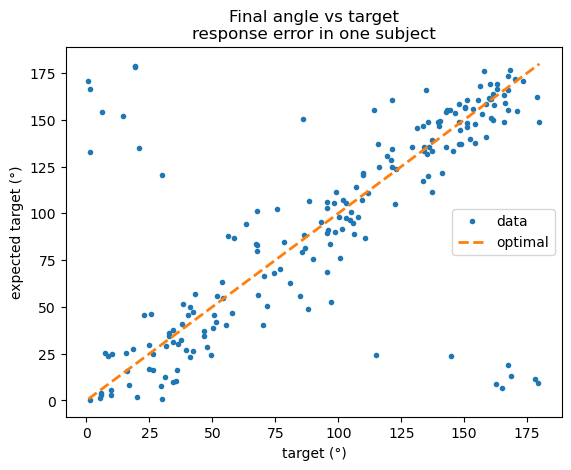

In [10]:
plt.plot(df_radian['target'].apply(np.rad2deg)%180, df_radian['final_angle'].apply(np.rad2deg)%180,".", label = "data")
plt.xlabel("target (°)")
cutoff = np.rad2deg(df_radian['target'])%180
plt.plot(np.linspace(min(cutoff),max(cutoff)), np.linspace(min(cutoff),max(cutoff)), "--", linewidth =2, label = "optimal")
plt.ylabel("expected target (°)")
plt.title("Final angle vs target\nresponse error in one subject")
plt.legend()
plt.show()

### Rotation proportions

In [11]:
# 1. Find all unique angles
all_angles = set()
for lst in df_filtered["stimulus_rotations"]:
    all_angles.update(lst)

# 2. Proportion of sequences that contain each 3 angles (0°, +45°, -45°)
angle_presence = {}
total_lists = len(df_filtered["stimulus_rotations"])
for angle in all_angles:
    count = sum(angle in lst for lst in df_filtered["stimulus_rotations"])
    angle_presence[angle] = count / total_lists * 100  # in %

print("Proportion of sequences that contain each 3 angles (%) :")
for angle, pct in angle_presence.items():
    print(f"Angle {angle}: {pct:.1f}% ")

# 3. total frequency of each angle :
all_occurrences = [angle for lst in df_filtered["stimulus_rotations"] for angle in lst]
freq = Counter(all_occurrences)

print("\ntotal frequency of each angle (number of occurence) :")
for angle, count in freq.items():
    print(f"Angle {angle}: {count}")

Proportion of sequences that contain each 3 angles (%) :
Angle 0.0: 67.8% 
Angle -45.0: 69.3% 
Angle 45.0: 63.8% 

total frequency of each angle (number of occurence) :
Angle -45.0: 281
Angle 45.0: 245
Angle 0.0: 269


In [12]:
df_filtered['length_of_sequence'] = df_filtered['stimulus_rotations'].apply(len)

only_45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == 45.0 for angle in x))]
only_minus45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == -45.0 for angle in x))]

only_minus45_filtered = only_minus45[only_minus45['length_of_sequence'] > 1]
only_45_filtered = only_45[only_45['length_of_sequence'] > 1]

print("Sequences 100% of +45° and length > 1 :")
print("there are", len(only_45), "sequences 100% of +45° in total, and", len(only_45_filtered),"sequences of 1 element +45°")


print("\nSequences 100% of -45° and length > 1 :")
print("there are", len(only_minus45), "sequences 100% of -45° in total, and", len(only_minus45_filtered),"sequences of 1 element -45°")



Sequences 100% of +45° and length > 1 :
there are 19 sequences 100% of +45° in total, and 2 sequences of 1 element +45°

Sequences 100% of -45° and length > 1 :
there are 21 sequences 100% of -45° in total, and 3 sequences of 1 element -45°


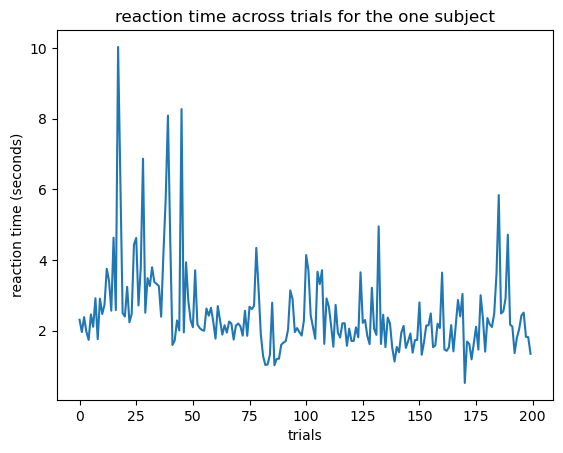

In [13]:
plt.plot(df_filtered["trial_rt"]*10**-3)
plt.title("reaction time across trials for the one subject")
plt.xlabel("trials")
plt.ylabel("reaction time (seconds)")
plt.show()

### Subject's score

In [14]:
print("the subject's score is :",df_radian["score"].sum())

the subject's score is : 1364


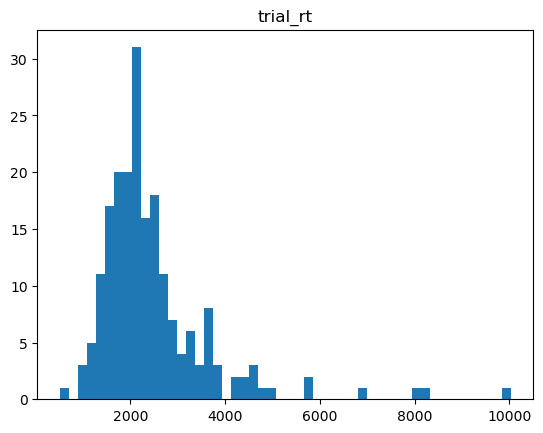

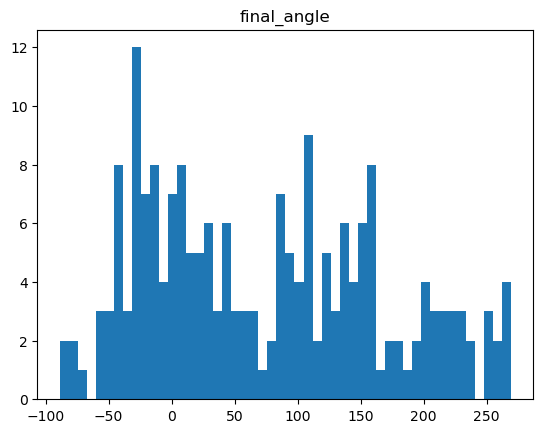

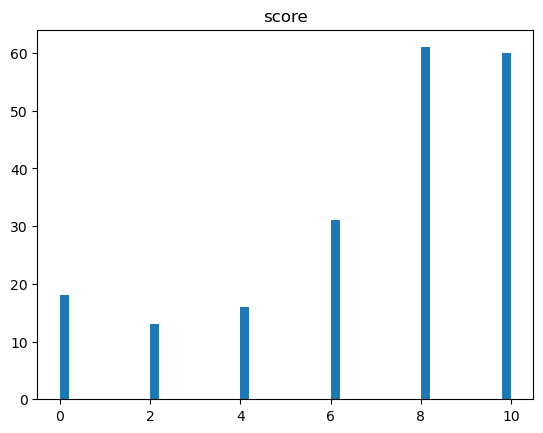

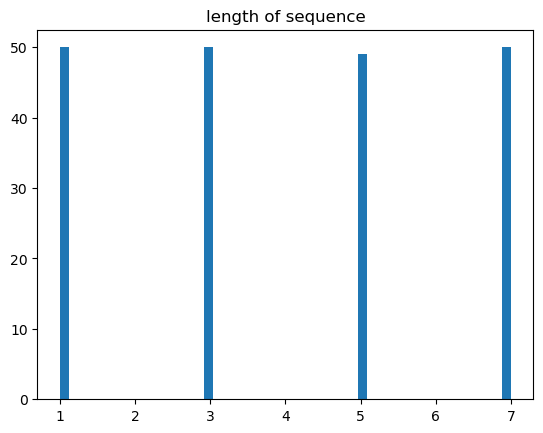

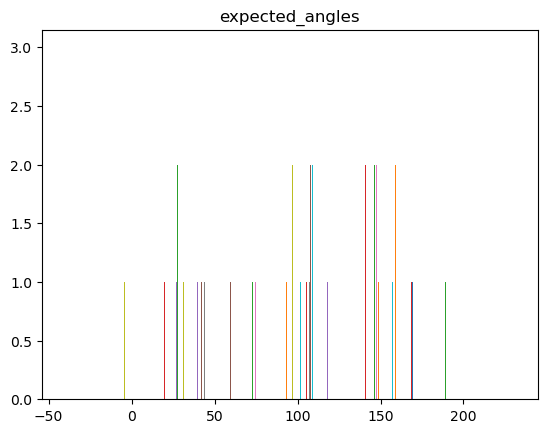

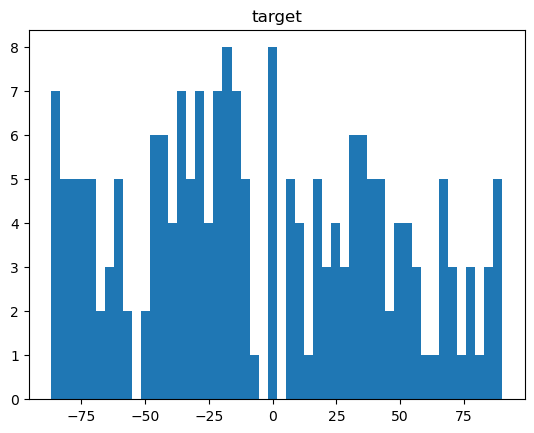

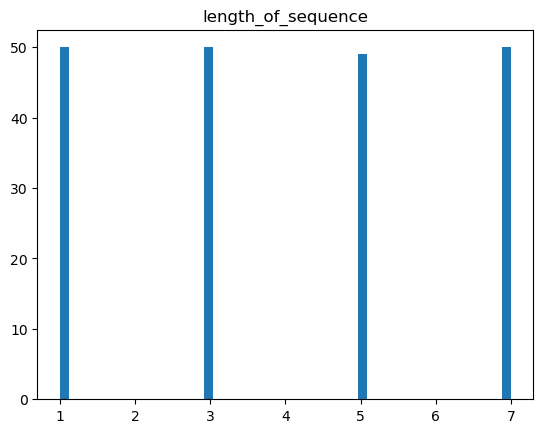

In [15]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

### Metadata exploration on all participants

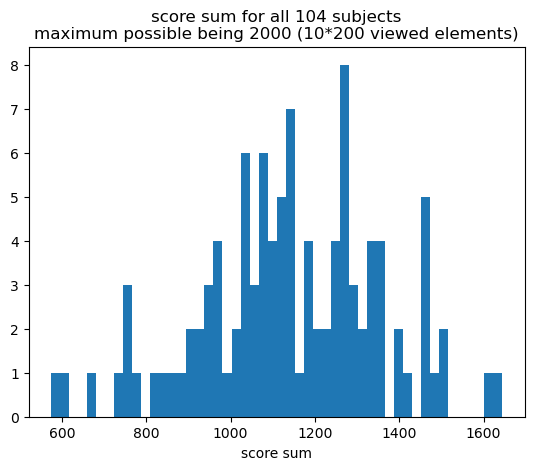

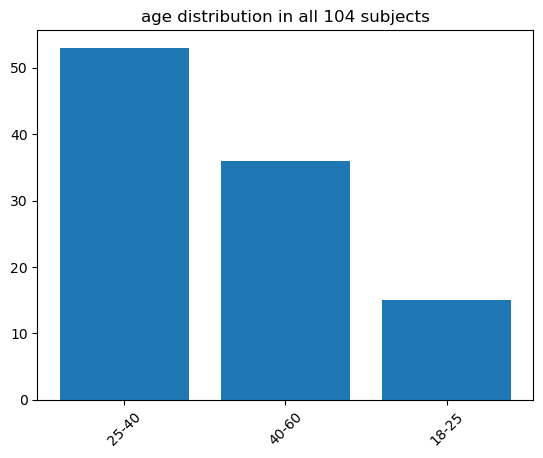

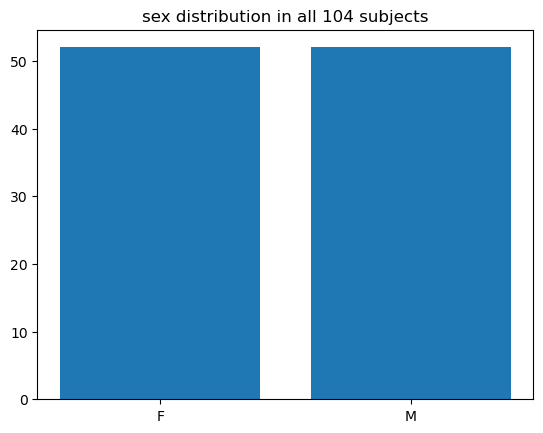

In [16]:
filepaths = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/Data/Rotations/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sex_tot = []
    for df in dfs :    
        survey = df[df["trial_type"] == "survey-dropdown"]
        if len(survey) == 0:
            age, sex = None, None
        else:
            resp = json.loads(survey.iloc[0]["responses"])
            age = resp.get("0")
            sex = resp.get("1")        
        age_tot.append(age)
        sex_tot.append(sex)
        
        df_filtered = df[df["stimulus_rotations"].notna()].copy()
        df_filtered = df_filtered.dropna(subset=["final_angle"]).copy()
        
        df_filtered['score'] = pd.to_numeric(df_filtered["score"], errors="coerce")
        score_sum.append(df_filtered["score"].sum(skipna=True))
        
    return score_sum, age_tot, sex_tot

scores, ages, sexs = data_sujets(dfs)

plt.hist(scores, bins=50)
plt.title(f"score sum for all {len(scores)} subjects\nmaximum possible being 2000 (10*200 viewed elements)")
plt.xlabel("score sum")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/somme des scores par sujet.pdf")
plt.show()

age_counts = pd.Series(ages).value_counts(dropna=False)
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xticks(rotation=45)
plt.title(f"age distribution in all {len(scores)} subjects")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/distribution des ages.pdf")
plt.show()

sex_counts = pd.Series(sexs).value_counts(dropna=False)
plt.bar(sex_counts.index.astype(str), sex_counts.values)
plt.title(f"sex distribution in all {len(scores)} subjects")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/distribution des sexes.pdf")
plt.show()

In [17]:
scores_x_sex = pd.DataFrame(scores, columns = ["scores"])
scores_x_sex["sexs"] = sexs
scores_x_sex

,scores,sexs
0,1390.0,F
1,1362.0,M
2,1218.0,M
3,1046.0,F
4,1318.0,M
...,...,...
99,1176.0,M
100,782.0,F
101,764.0,F
102,1344.0,M


t = 0.16779046748070495
p = 0.8670803545330716


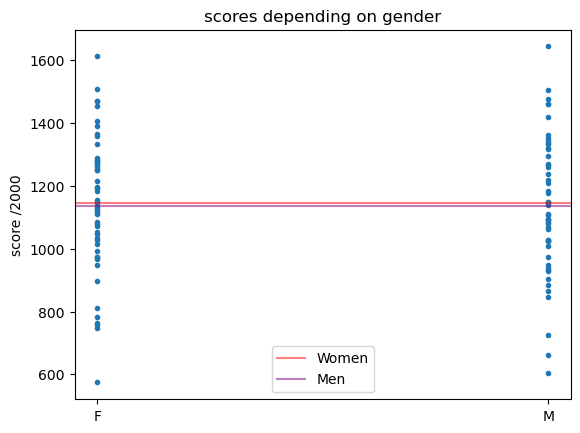

In [18]:
plt.plot(sexs, scores, '.')
plt.axhline(np.mean(scores_x_sex["scores"].loc[scores_x_sex["sexs"]=="F"]), color = "red", alpha = 0.5, label = "Women")
plt.axhline(np.mean(scores_x_sex["scores"].loc[scores_x_sex["sexs"]=="M"]), color = "purple", alpha = 0.5, label = "Men")
plt.legend()
plt.title("scores depending on gender")
plt.ylabel("score /2000")

from scipy.stats import ttest_ind

scores_F = scores_x_sex["scores"].loc[scores_x_sex["sexs"]=="F"]
scores_M = scores_x_sex["scores"].loc[scores_x_sex["sexs"]=="M"]
t, p = ttest_ind(scores_F, scores_M, nan_policy="omit")
print("t =", t)
print("p =", p)

In [19]:
print("there are",sexs.count('F'), "women")
print("there are",sexs.count('M'), 'men')
print("there are",ages.count('18-25'), "subjects that are between 18 and 25 years old")
print("there are",ages.count('25-40'), 'subjects that are between 25 and 40 years old')
print("there are",ages.count('40-60'), 'subjects that are between 40 and 60 years old')

there are 52 women
there are 52 men
there are 15 subjects that are between 18 and 25 years old
there are 53 subjects that are between 25 and 40 years old
there are 36 subjects that are between 40 and 60 years old


### Angle disposition on circle

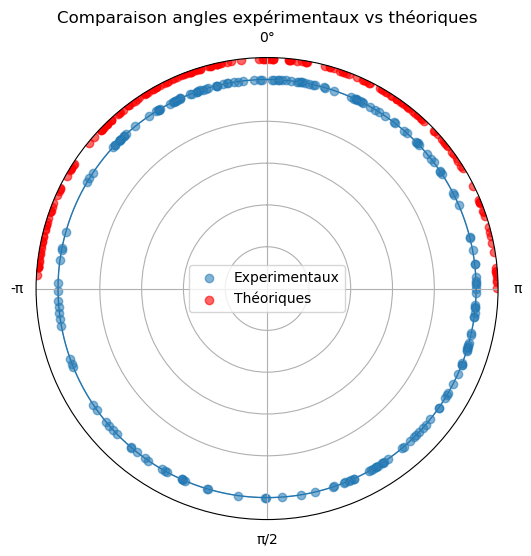

In [20]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.set_theta_zero_location("N")   # 0° à gauche (comme ton choix)
ax.set_theta_direction(-1)        # sens horaire

# ---- CERCLE TRIGONOMÉTRIQUE ----
theta = np.linspace(0, np.pi*2, 400)
ax.plot(theta, np.ones_like(theta), linewidth=1)  # cercle unité

# labels angulaires
ax.set_thetagrids(
    angles=[0, 90, 180, 270],
    labels=["0°", "π", "π/2", "-π"]
)

# ---- TES DONNÉES ----
theta_presented = df_radian['final_angle'].values
theta_targets = df_radian['target'].values

ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])   # enlève les labels du rayon
ax.set_title("Comparaison angles expérimentaux vs théoriques")
ax.legend()

plt.show()

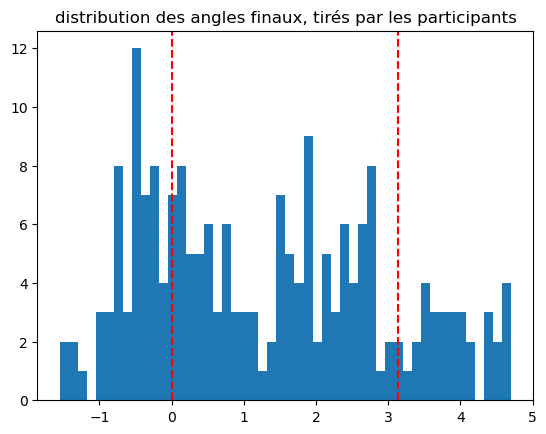

In [21]:
plt.hist(df_radian["final_angle"], bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(np.pi, color='red', linestyle='--')
plt.title("distribution des angles finaux, tirés par les participants")
plt.show()

## **Performances**

### Did the participants responded well ? (error between final angle and the target angle) 

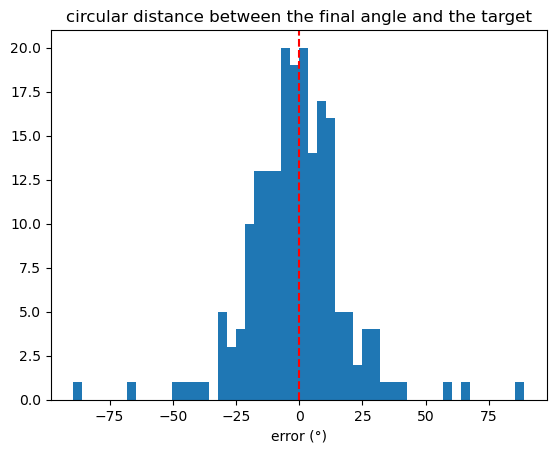

In [22]:
plt.hist(np.rad2deg(df_radian["error_to_target"]), bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("error (°)")
plt.title("circular distance between the final angle and the target")
plt.show()

### Did the participants ignored the rotations ? (take into account only the orientations that they have seen, without rotating the stimulus)

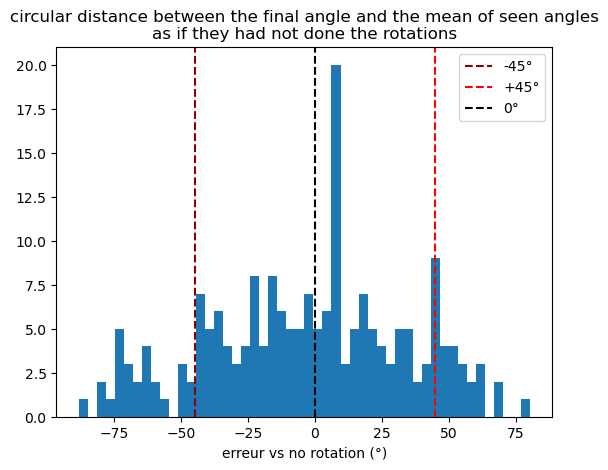

In [23]:
plt.hist(np.rad2deg(df_radian["error_wo_rotation"]), bins=50)
plt.axvline(-45, color='darkred', linestyle='--', label="-45°") 
plt.axvline(45, color='red', linestyle='--', label="+45°") 
plt.axvline(0, color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs no rotation (°)")
plt.title("circular distance between the final angle and the mean of seen angles\nas if they had not done the rotations")
plt.legend()
plt.show()

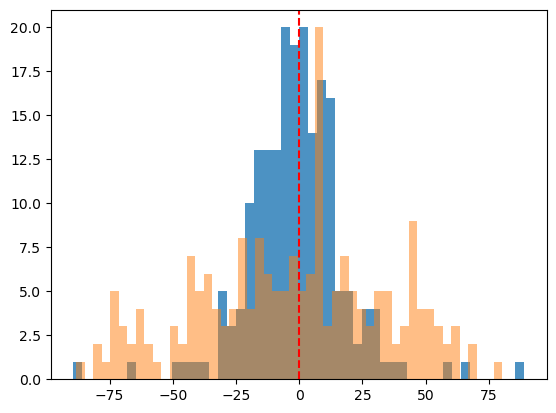

In [24]:
plt.hist(np.rad2deg(df_radian["error_to_target"]), bins=50, alpha =0.8)
plt.hist(np.rad2deg(df_radian["error_wo_rotation"]), bins=50, alpha =0.5)
plt.axvline(0, color='red', linestyle='--') 



### Mean rotations VS errors

mean rotation vs error to target : the response error

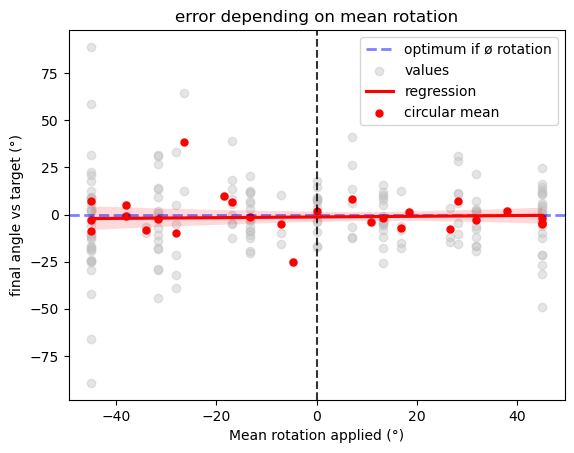

In [25]:
x = (df_radian.groupby("mean_rotation")["error_to_target"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum if ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_to_target"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
plt.scatter(x["mean_rotation"], x["error_to_target"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("final angle vs target (°)")
plt.title("error depending on mean rotation")
plt.legend()
plt.show()

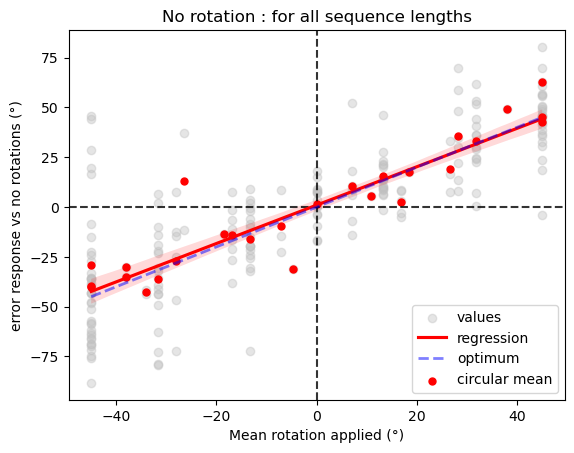

In [26]:
x = (df_radian.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
borne = x["mean_rotation"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error response vs no rotations (°)")
plt.title("No rotation : for all sequence lengths")
plt.legend()
plt.show()

plot pour différentes tailles de séquences

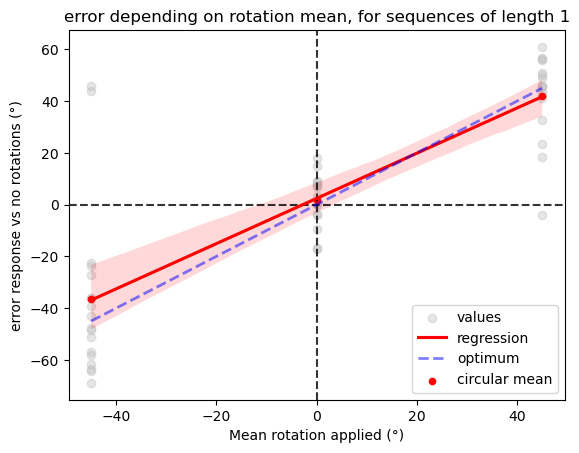

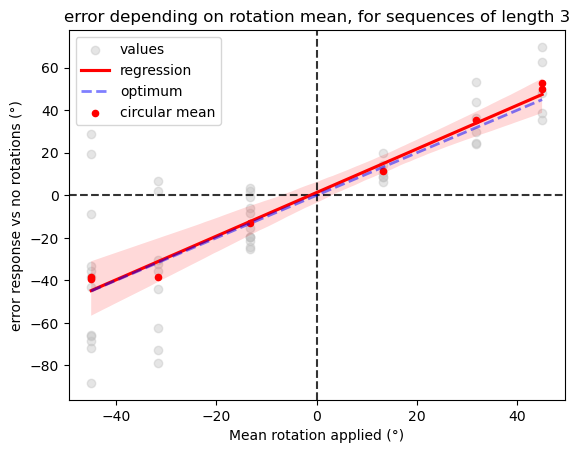

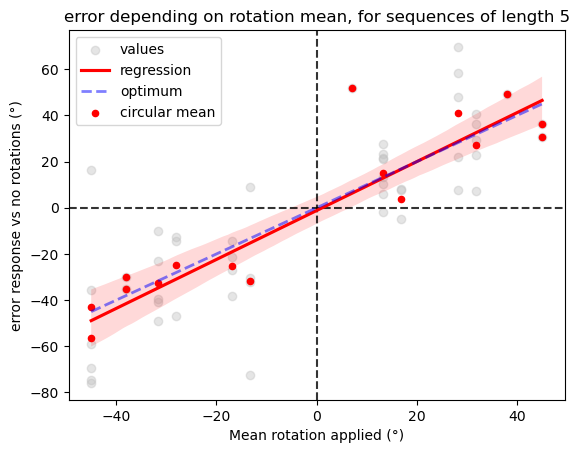

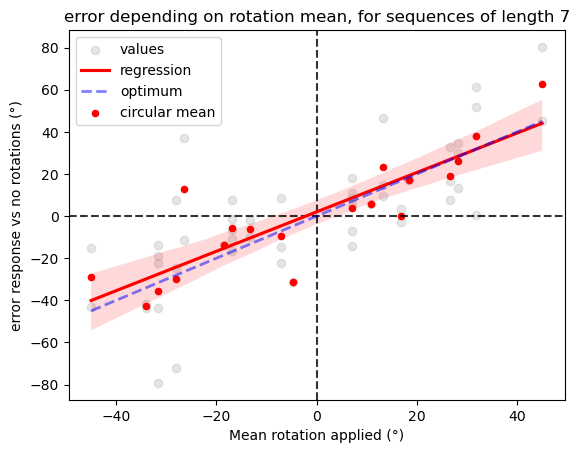

In [27]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation"]
    sns.regplot(x=df_radian[df_radian["length of sequence"]==seqlen]["mean_rotation"].apply(np.rad2deg), y=df_radian[df_radian["length of sequence"]==seqlen]["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=20, label="circular mean")

    plt.xlabel("Mean rotation applied (°)")
    plt.ylabel("error response vs no rotations (°)")    
    plt.title(f"error depending on rotation mean, for sequences of length {seqlen}")
    plt.legend()
    plt.show()

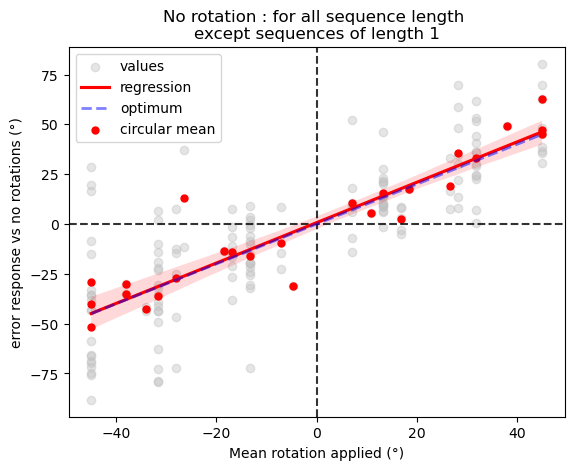

In [28]:
df = df_radian[df_radian["length of sequence"]!=1]

x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

borne = x["mean_rotation"]
sns.regplot(x=df["mean_rotation"].apply(np.rad2deg), y=df["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error response vs no rotations (°)")    
plt.title("No rotation : for all sequence length \nexcept sequences of length 1")
plt.legend()
plt.show()

## **Reaction time**

### RT vs error

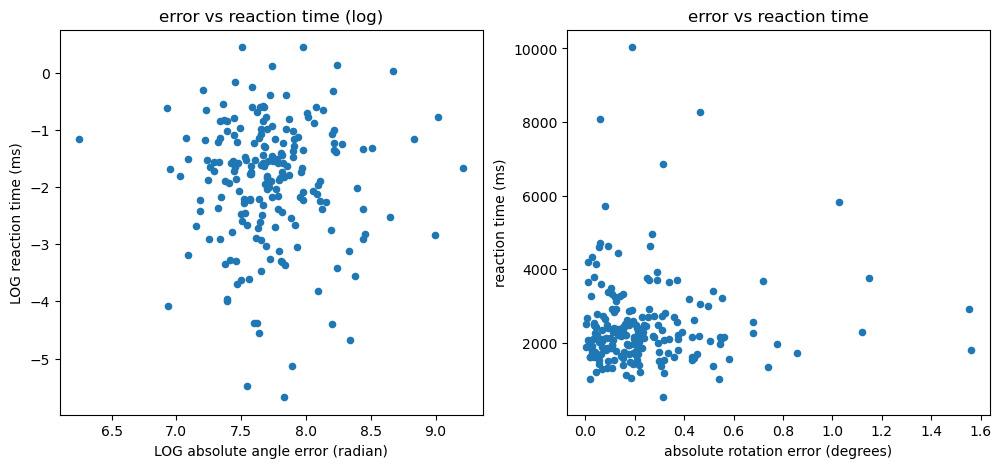

In [29]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.scatter(df_radian["trial_rt"].apply(np.log), np.abs(df_radian["error_to_target"]).apply(np.log), s=20)
plt.xlabel("LOG absolute angle error (radian)")
plt.ylabel("LOG reaction time (ms)")
plt.title("error vs reaction time (log)")

plt.subplot(1,2,2) 
plt.scatter(np.abs(df_radian["error_to_target"]), df_radian["trial_rt"], s=20)
plt.xlabel("absolute rotation error (degrees)")
plt.ylabel("reaction time (ms)")
plt.title("error vs reaction time")
plt.show()

### error vs le temps

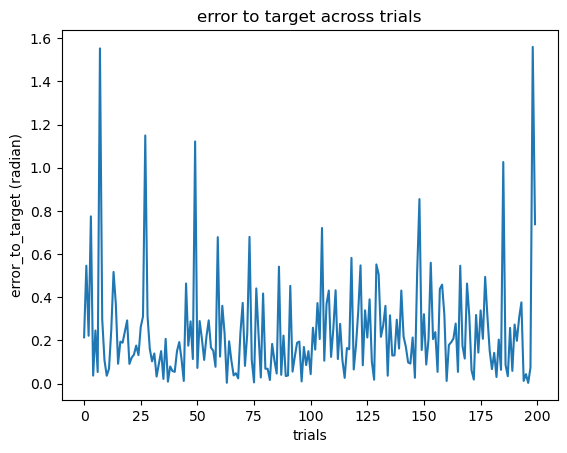

In [30]:
plt.plot(np.abs(df_radian["error_to_target"]))
plt.xlabel("trials")
plt.ylabel("error_to_target (radian)")
plt.title("error to target across trials")
plt.show()

### RT vs time

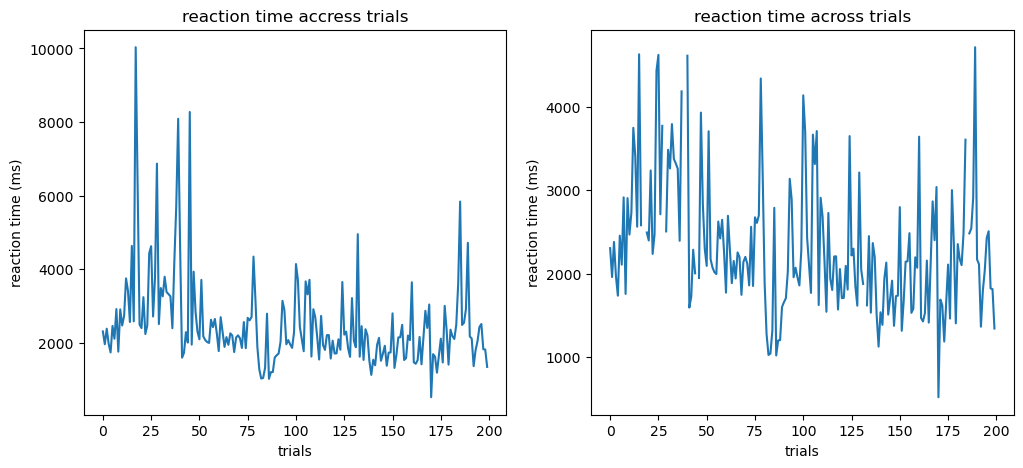

In [31]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(np.abs(df_radian["trial_rt"]))
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
plt.title("reaction time accress trials")

mean_rt = df_radian["trial_rt"].mean()
std_rt = df_radian["trial_rt"].std()
upper_threshold = mean_rt + 2*std_rt

rt_filtered = df_radian["trial_rt"].copy()
rt_filtered[(rt_filtered > upper_threshold)] = np.nan

plt.subplot(1,2,2)
plt.plot(rt_filtered)
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
plt.title("reaction time across trials")
plt.show()

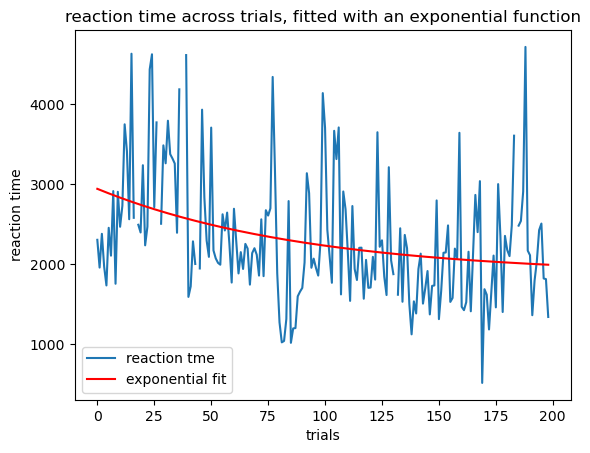

In [32]:
from scipy.optimize import curve_fit

y = rt_filtered.values.astype(float)
x = np.arange(len(y))

mask = np.isfinite(y)
x_clean = x[mask]
y_clean = y[mask]

# exponential model
def exp_model(x, a, b, c):
    return a * np.exp(-b * x) + c

# fit
params, _ = curve_fit(
    exp_model,
    x_clean,
    y_clean,
    p0=[1000, 0.01, 2000],   # best guesses
    maxfev=10000          
)

a, b, c = params

y_fit_full = exp_model(x, a, b, c)

plt.plot(x, y, label="reaction tme")
plt.plot(x, y_fit_full, "r", label="exponential fit")
plt.legend()
plt.xlabel("trials")
plt.ylabel("reaction time")
plt.title("reaction time across trials, fitted with an exponential function")
plt.show()

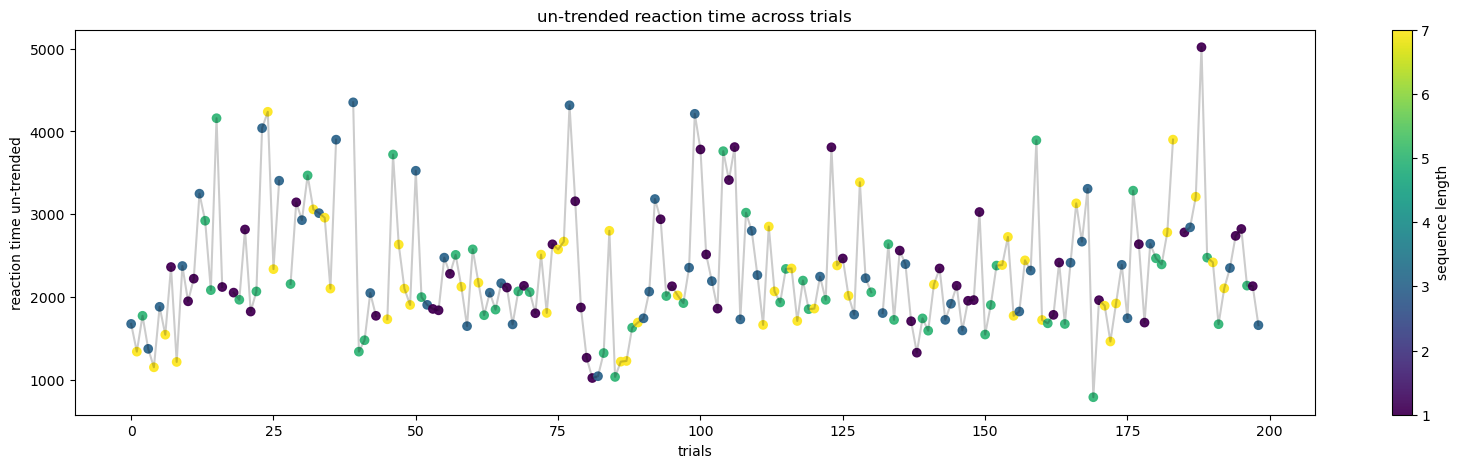

In [33]:
seq = df_radian["length of sequence"].values

plt.figure(figsize=(20,5))

residuals = y - y_fit_full
residuals = y - y_fit_full + np.mean(y_fit_full)
plt.plot(x, residuals, color = "black", alpha = 0.2)
plt.scatter(x, residuals, c=seq, cmap="viridis", alpha=0.95)
plt.colorbar(label="sequence length")
plt.axhline(np.mean(residuals), color="black", linestyle="--")
plt.xlabel("trials")
plt.ylabel("reaction time un-trended")
plt.title("un-trended reaction time across trials")
plt.show()


### RT vs seq length

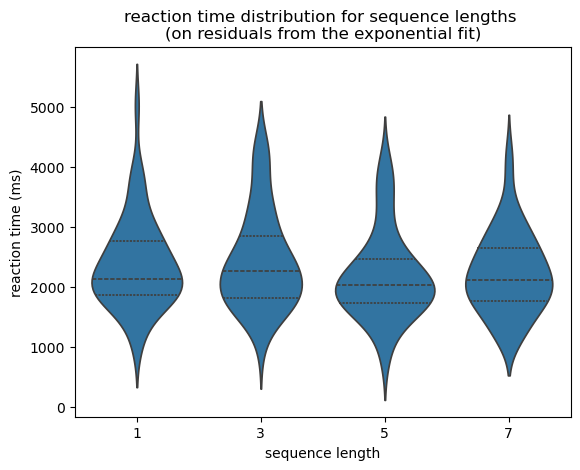

In [34]:
sns.violinplot(x=seq, y=residuals, inner="quartile")

plt.xlabel("sequence length")
plt.ylabel("reaction time (ms)")
plt.title("reaction time distribution for sequence lengths \n(on residuals from the exponential fit)")

plt.show()

### RT vs score

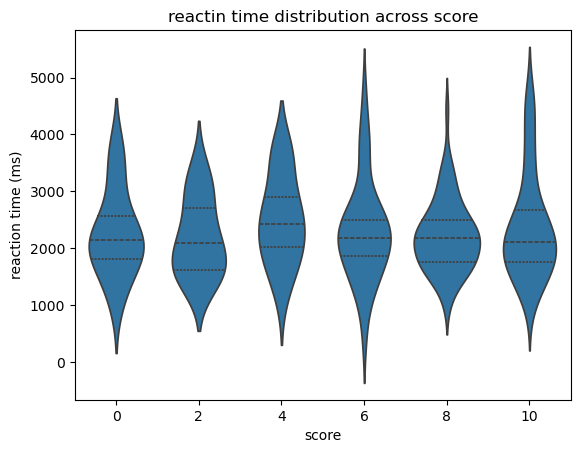

In [35]:
sns.violinplot(x="score", y=rt_filtered, data=df_radian, inner="quartile")

plt.xlabel("score")
plt.ylabel("reaction time (ms)")
plt.title("reactin time distribution across score")

plt.show()

## Analyses pour tous les participants

In [36]:
def mean_par_sujet (column) : # gives one value per subject
    df_participant = pd.DataFrame()
    for participant in range(104):
        df_participant[participant] = all_participants(dfs[participant])[column]
    mean_matrix = df_participant.mean()
    return mean_matrix      

In [37]:
def sd_par_sujet (column) : 
    df_participant = pd.DataFrame()
    for participant in range(104):
        df_participant[participant] = all_participants(dfs[participant])[column]
    mean_matrix = df_participant.std()
    return mean_matrix      

In [38]:
def circular_std_rad(angles):
    angles = np.asarray(angles, dtype=float)
    angles = angles[~np.isnan(angles)]

    if len(angles) == 0:
        return np.nan

    R = np.sqrt(np.mean(np.cos(angles))**2 + np.mean(np.sin(angles))**2)
    return np.sqrt(-2 * np.log(R))

### reaction time

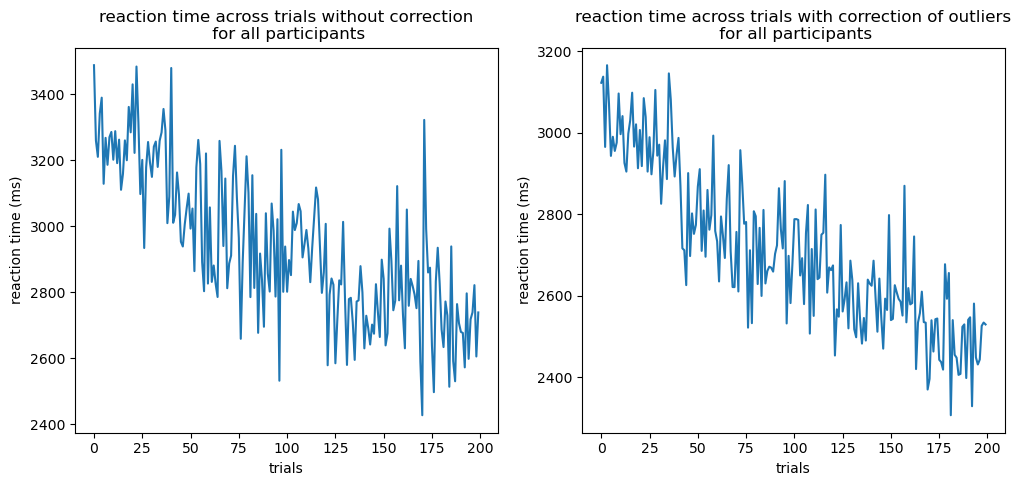

In [39]:
all_rt = []
for participant in dfs : 
    df_part = all_participants(participant)
    rt = df_part["trial_rt"].values
    all_rt.append(rt)
    
rt_matrix = np.full((len(all_rt), max(len(rt) for rt in all_rt)), np.nan)

for i, rt in enumerate(all_rt):
    rt_matrix[i, :len(rt)] = rt 
mean_rt = np.nanmean(rt_matrix, axis=0)

plt.subplots(1,2, figsize=(12,5))

# plot n°1
plt.subplot(1,2,1) 
plt.plot(mean_rt)
plt.title("reaction time across trials without correction\n for all participants")
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")


# plot n°2
# correction of higher RT values

all_rt_2 = []
for participant in dfs : 
    df_part = all_participants(participant)
    rt = df_part["trial_rt"].values
    mean_rt2 = rt.mean()
    std_rt = rt.std()
    upper_threshold = mean_rt2 + 2*std_rt

    rt_clean = rt.copy()
    rt_clean[rt_clean > upper_threshold] = np.nan
        
    all_rt_2.append(rt_clean)
    
rt_matrix_2 = np.full((len(all_rt_2), max(len(rt) for rt in all_rt_2)), np.nan)

for i, rt in enumerate(all_rt_2):
    rt_matrix_2[i, :len(rt)] = rt 
mean_rt3 = np.nanmean(rt_matrix_2, axis=0)

plt.subplot(1,2,2) 
plt.plot(mean_rt3)
plt.title("reaction time across trials with correction of outliers\n for all participants")
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/temps de réaction de tous les sujets.pdf")
plt.show()

### Distribution of final angles

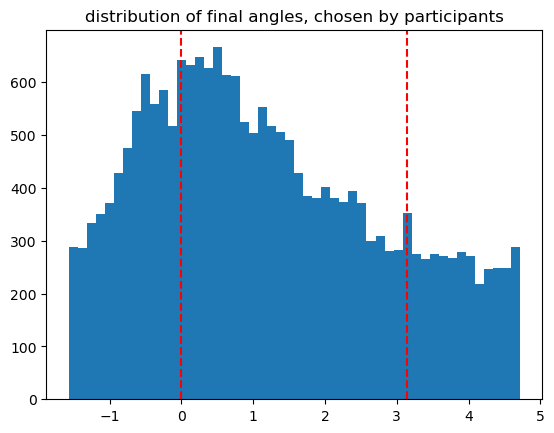

In [40]:
all_final_angles = []

for participant in dfs:
    df_part = all_participants(participant)
    all_final_angles.extend(df_part["final_angle"].values)

all_final_angles = np.array(all_final_angles)


plt.hist(all_final_angles, bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(np.pi, color='red', linestyle='--')
plt.title("distribution of final angles, chosen by participants")
plt.show()

### distance/erreur à la target

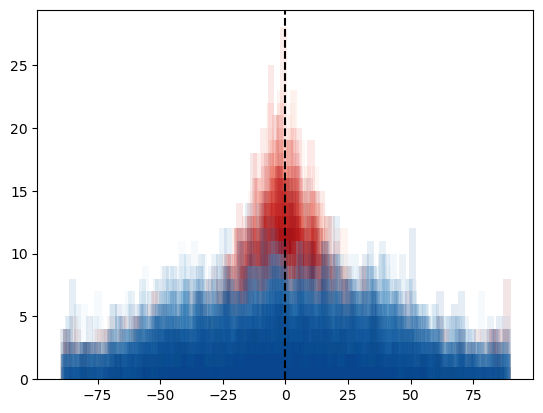

In [41]:
plt.figure()

n_lines = len(dfs)
colors_red = plt.cm.Reds(np.linspace(0.2, 0.95, n_lines))
colors_blue = plt.cm.Blues(np.linspace(0.2, 0.95, n_lines))


for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    errors = df_part["error_to_target"].apply(np.rad2deg).values
    plt.hist(errors, color=colors_red[participant], bins=60, alpha=0.1)

plt.axvline(0, color='black', linestyle='--')

for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    errors = df_part["error_wo_rotation"].apply(np.rad2deg).values
    plt.hist(errors,color=colors_blue[participant], bins=60, alpha =0.1)

# plt.xlabel("final angle vs target (°)")
# plt.title("circular error between the target and final angle\nfor all paticipants")
plt.show()

In [42]:
errors_target_all_hist = [] # radian
errors_target_all = []
errors_wo_rot_all_hist = [] # radian
errors_wo_rot_all = []

for df in dfs:
    df_part = all_participants(df)
    errors_target_all_hist.extend(df_part["error_to_target"].values)
    errors_wo_rot_all_hist.extend(df_part["error_wo_rotation"].values)
    errors_target_all.append(df_part["error_to_target"].values)
    errors_wo_rot_all.append(df_part["error_wo_rotation"].values)



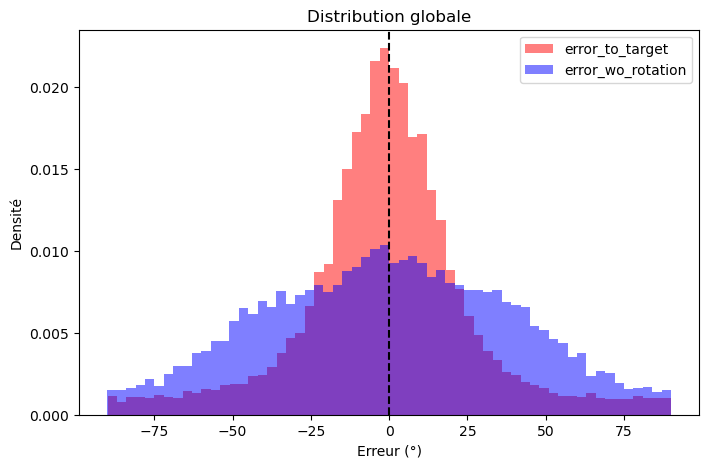

In [43]:
plt.figure(figsize=(8, 5))

plt.hist(np.rad2deg(errors_target_all_hist), bins=60, alpha=0.5, density=True, color="red", label="error_to_target")
plt.hist(np.rad2deg(errors_wo_rot_all_hist), bins=60, alpha=0.5, density=True, color="blue", label="error_wo_rotation")

plt.axvline(0, color='black', linestyle='--')
plt.legend()
plt.xlabel("Erreur (°)")
plt.ylabel("Densité")
plt.title("Distribution globale")
plt.show()

In [44]:
bins = np.linspace(np.deg2rad(-100), np.deg2rad(+100), 61)
centers = (bins[:-1] + bins[1:]) / 2

hists_target = []
hists_wo = []

for df in dfs:
    df_part = all_participants(df)

    e1 = df_part["error_to_target"].values
    e2 = df_part["error_wo_rotation"].values

    h1, _ = np.histogram(e1, bins=bins, density=True)
    h2, _ = np.histogram(e2, bins=bins, density=True)

    hists_target.append(h1)
    hists_wo.append(h2)

hists_target = np.array(hists_target)
hists_wo = np.array(hists_wo)

mean_target = hists_target.mean(axis=0)
std_target = hists_target.std(axis=0)

mean_wo = hists_wo.mean(axis=0)
std_wo = hists_wo.std(axis=0)


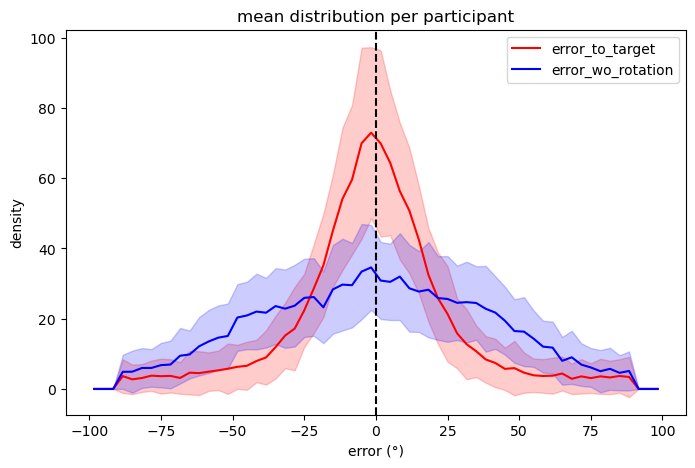

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(np.rad2deg(centers), np.rad2deg(mean_target), color="red", label="error_to_target")
plt.fill_between(np.rad2deg(centers), np.rad2deg(mean_target) - np.rad2deg(std_target), np.rad2deg(mean_target) + np.rad2deg(std_target),
                 color="red", alpha=0.2)

plt.plot(np.rad2deg(centers), np.rad2deg(mean_wo), color="blue", label="error_wo_rotation")
plt.fill_between(np.rad2deg(centers), np.rad2deg(mean_wo) - np.rad2deg(std_wo), np.rad2deg(mean_wo) + np.rad2deg(std_wo),
                 color="blue", alpha=0.2)

plt.axvline(0, color='black', linestyle='--')
plt.xlabel("error (°)")
plt.ylabel("density")
plt.title("mean distribution per participant")
plt.legend()
plt.show()

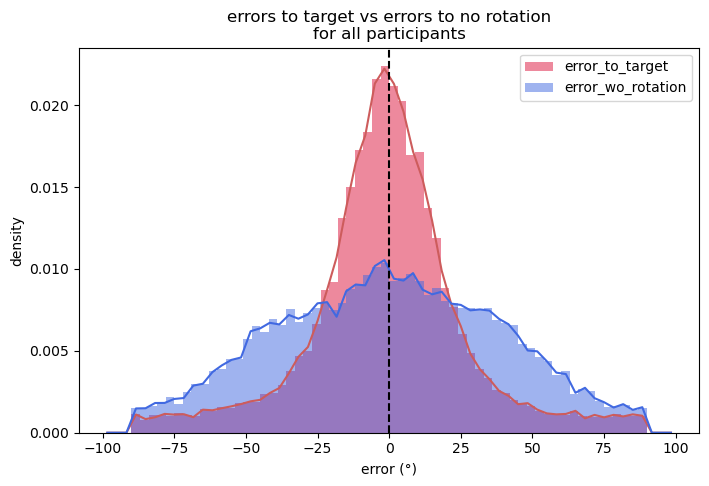

In [46]:
plt.figure(figsize=(8, 5))
plt.hist(np.rad2deg(errors_target_all_hist), bins=60, alpha=0.5, density=True, color="crimson", label="error_to_target")
plt.plot(np.rad2deg(centers), mean_target*np.pi/180, color="indianred")
# plt.fill_between(centers, mean_target - std_target, mean_target + std_target, color="red", alpha=0.1)


plt.hist(np.rad2deg(errors_wo_rot_all_hist), bins=60, alpha=0.5, density=True, color="royalblue", label="error_wo_rotation")
plt.plot(np.rad2deg(centers), mean_wo*np.pi/180, color="royalblue")
# plt.fill_between(centers, mean_wo - std_wo, mean_wo + std_wo, color="blue", alpha=0.1)

plt.axvline(0, color='black', linestyle='--')
plt.xlabel("error (°)")
plt.ylabel("density")
plt.title("errors to target vs errors to no rotation\nfor all participants")
plt.legend()
plt.show()

In [47]:
errors_target_all_abs = np.abs(errors_target_all)
errors_wo_rot_all_abs = np.abs(errors_wo_rot_all)
errors_target_all_hist_abs = np.abs(errors_target_all_hist)
errors_wo_rot_all_hist_abs = np.abs(errors_wo_rot_all_hist)

In [48]:
bins_abs = np.linspace(0, np.deg2rad(100), 61)
centers_abs = (bins_abs[:-1] + bins_abs[1:]) / 2

hists_target_abs = []
hists_wo_abs = []

for df in dfs:
    df_part = all_participants(df)

    e1 = np.abs(df_part["error_to_target"].values)
    e2 = np.abs(df_part["error_wo_rotation"].values)

    h1, _ = np.histogram(e1, bins=bins_abs, density=True)
    h2, _ = np.histogram(e2, bins=bins_abs, density=True)

    hists_target_abs.append(h1)
    hists_wo_abs.append(h2)

hists_target_abs = np.array(hists_target_abs)
hists_wo_abs = np.array(hists_wo_abs)

mean_target_abs = hists_target_abs.mean(axis=0)
std_target_abs = hists_target_abs.std(axis=0)

mean_wo_abs = hists_wo_abs.mean(axis=0)
std_wo_abs = hists_wo_abs.std(axis=0)


In [ ]:
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import PCA
from scipy.optimize import fmin


def f(x, a, b, c):
    return a*x**2 + b*x + c

def sse(p, x, y):
    return np.sum((f(x, *p) - y)**2)






data = df[f"patient {i}"].dropna()

hist, bins = np.histogram(data, bins=50, density=True)
X = (bins[:-1] + bins[1:]) / 2

p0 = [0.5,  0.5, 0.5]
p_opt = fmin(sse, p0, args=(X, y))

y_fit = f(X, *p_opt)

X_fit = np.linspace(X.min(), X.max(), 100)

plt.hist(data, bins=50, density=True, alpha=0.5)
plt.plot(X_fit, poly(X_fit), color='red')
plt.show()

# DEFINITION DU POLYNOME
dg=2
def f(X,a,b,c):
    fx=a*X**2+b*X+c
    return fx

a,b,c=0.5,  0.5, 0.5

y = 

def sse(p):
    a,b,c,d,e=p
    d=np.sum(((f(X,a,b,c,d,e))- y)**2)
    return d
p0=-8.88612724e-8,  1.12854316e-2,  7.04081842e-08,  9.33158278e-10,-1.98918766e-7
p_opt=fmin(sse,p0)
a,b,c,d,e=p_opt
fx=f(X,a,b,c,d,e)

X=np.linspace(min(h),max(h),50)
parameters_sc.append(p_opt)

plt.figure()
plt.plot(X,fx,label="f(x) fitted")
plt.hist(df[f"patient {i}"].dropna(), bins=50, density=True, alpha=0.5, label='données brutes',linewidth=2) 
plt.legend()
plt.title(f"[TISSU ADIPEUX SOUS CUTANÉ]\nhistogramme données brutes + polynome\n du patient {i}")
plt.xlabel("taille des adipocytes (µm)")
plt.ylabel("frequence")
plt.savefig(f"/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/histos/degré {dg}/sous cutané/TA_sc histo +f(x) patient {i}.pdf")    
plt.close()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Optimization terminated successfully.
         Current function value: 0.001300
         Iterations: 183
         Function evaluations: 339


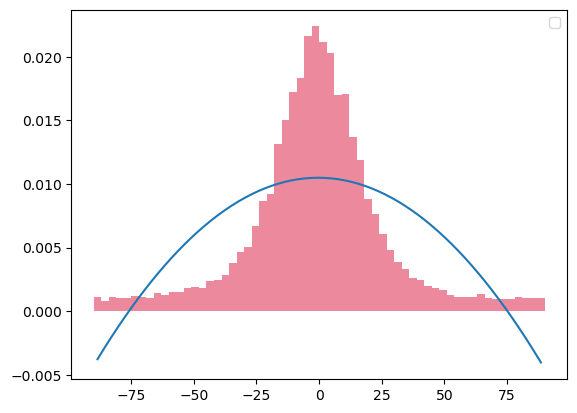

In [90]:
data = np.rad2deg(errors_target_all_hist)
data = data[np.isfinite(data)]  # enlève NaN + inf

hist, bins = np.histogram(data, bins=60, density=True)
X = (bins[:-1] + bins[1:]) / 2
y = hist

def sse(p):
    a,b,c=p
    d=np.sum(((f(X,a,b,c))- y)**2)
    return d

p0=0.5,0.5,0.5  
p_opt=fmin(sse,p0)
a,b,c=p_opt

def f(X,a,b,c):
    fx=a*X**2+b*X+c
    return fx

X_fit = np.linspace(X.min(), X.max(), 200)
fx=f(X_fit,a,b,c)

plt.plot(X_fit, fx)


plt.hist(data, bins=60, density=True, alpha=0.5, color="crimson")
# plt.plot(X_fit, poly(X_fit), color="darkred", label="fit poly")
plt.legend()

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(np.rad2deg(errors_target_all_hist), bins=60, alpha=0.5, density=True, color="crimson", label="error_to_target")
plt.plot(np.rad2deg(centers), mean_target*np.pi/180, color="indianred")
# plt.fill_between(centers, mean_target - std_target, mean_target + std_target, color="red", alpha=0.1)


plt.hist(np.rad2deg(errors_wo_rot_all_hist), bins=60, alpha=0.5, density=True, color="royalblue", label="error_wo_rotation")
plt.plot(np.rad2deg(centers), mean_wo*np.pi/180, color="royalblue")
# plt.fill_between(centers, mean_wo - std_wo, mean_wo + std_wo, color="blue", alpha=0.1)

plt.axvline(0, color='black', linestyle='--')
plt.xlabel("error (°)")
plt.ylabel("density")
plt.title("errors to target vs errors to no rotation\nfor all participants")
plt.legend()
plt.show()

In [ ]:


#%% fonction de lissage de courbe

def smooth(h,w):
    a = np.zeros(len(h))
    nx = len(h)
    for i in range(nx):
        if i<w :
            a[i] = np.sum(h[0:i+w])/(w+i)

        elif i+w > nx:
            a[i] = np.sum(h[i-w:])/(w + nx - i)
        else:
            a[i] = np.sum(h[i-w:i+w])/(2*w)
    return a

w=5
   
frequences_sc=[]
for patient in range(1,len(df.columns)+1) :     # pour chaque patient je veux la courbe de fréquence associée à son histogramme
    h=df[f"patient {patient}"].dropna()         # h c'est toute la colonne associée au patient 'patient' 
    
    histo1=np.histogram(h,bins=50,density=True)      # récupère les valeurs de l'histogramme : abscisse et ordonnées
    X=np.linspace(min(h),max(h),50)
    data = histo1[0]                                # data : abscisses de l'histo
    
    frequences_sc.append(smooth(data,w))                     # on met dans une liste toutes les fréquences pour 1 patient
    

#%% SOUS CUTANE -- plot des histogrammes

parameters_sc=[]
for i in range(1,len(df.columns)+1):
    h=df[f"patient {i}"].dropna() 

    y=frequences_sc[i-1]

    def sse(p):
        a,b,c,d,e=p
        d=np.sum(((f(X,a,b,c,d,e))- y)**2)
        return d

    p0=-8.88612724e-8,  1.12854316e-2,  7.04081842e-08,  9.33158278e-10,-1.98918766e-7

    p_opt=fmin(sse,p0)

    a,b,c,d,e=p_opt
    fx=f(X,a,b,c,d,e)
    
    parameters_sc.append(p_opt)
    
    plt.figure()
    plt.plot(X,fx,label="f(x) fitted")
    plt.hist(df[f"patient {i}"].dropna(), bins=50, density=True, alpha=0.5, label='données brutes',linewidth=2) 
    plt.legend()
    plt.title(f"[TISSU ADIPEUX SOUS CUTANÉ]\nhistogramme données brutes + polynome\n du patient {i}")
    plt.xlabel("taille des adipocytes (µm)")
    plt.ylabel("frequence")
    plt.savefig(f"/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/histos/degré {dg}/sous cutané/TA_sc histo +f(x) patient {i}.pdf")    
    plt.close()
 
#%% SOUS CUTANE -- test des paramètres


h=df["patient 16"].dropna() 

y, bins = np.histogram(h, bins=50, density=True)
X = 0.5 * (bins[:-1] + bins[1:])  # centres des bins → mêmes dimensions que y

def sse(p):
   a,b,c,d,e=p
   d=np.sum(((f(X,a,b,c,d,e))- y)**2)
   return d

p0=-8.88612724e-8,  1.12854316e-2,  7.04081842e-08,  9.33158278e-10,-1.98918766e-7

p_opt=fmin(sse,p0)

a,b,c,d,e=p_opt
fx=f(X,a,b,c,d,e)
    
parameters_sc.append(p_opt)
    
plt.figure()
plt.plot(X,fx,label="f(x) fitted")
plt.hist(df["patient 16"].dropna(), bins=50, density=True, alpha=0.5, label='données brutes',linewidth=2) 
plt.legend()
plt.title("[TISSU ADIPEUX SOUS CUTANÉ]\nhistogramme données brutes + polynome\n du patient 16")
plt.xlabel("taille des adipocytes (µm)")
plt.ylabel("frequence")
plt.savefig(f"/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/histos/degré {dg}/sous cutané/TA_sc histo +f(x) patient {i}.pdf")    
plt.show()
    


#%%  SOUS CUTANE -- CLUSTERING SPECTRAL
parameters_sc = np.array(parameters_sc)         # conversion en matrice

# Applique le clustering spectral
n=3
model = SpectralClustering(n_clusters=n, affinity='nearest_neighbors', assign_labels='kmeans')          # pas sure des trucs là
labels_sc = model.fit_predict(parameters_sc)


#%% SOUS CUTANE -- PCA

### APC
pca = PCA(n_components=2)
parameters_pca = pca.fit_transform(parameters_sc)

# plot PCA avec couleurs du clustering spectral
plt.figure(figsize=(8,6))
plt.scatter(parameters_pca[:, 0], parameters_pca[:, 1], c=labels_sc, cmap='viridis', s=40)   
plt.title(f"Clustering spectral sur polynome (n={n}) - tissu sous-cutané")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.grid(False)
plt.savefig(f"/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/clustering/degré {dg}/{n} clusters/clustering n={n} sous cutané sur polynome (spectral->PCA).pdf")    
plt.show()

#%% VISCERAL -- plot des histogrammes

parameters_om=[]
for i in range(1,len(odf.columns)+1):
    h=odf[f"patient {i}"].dropna() 

    # fit du polynome
    y, bins = np.histogram(h, bins=50, density=True)
    X = 0.5 * (bins[:-1] + bins[1:])  # centres des bins → mêmes dimensions que y

    def sse(p):
        a,b,c,d,e=p
        d=np.sum(((f(X,a,b,c,d,e))- y)**2)
        return d

    p0=-8.88612724e-8,  1.12854316e-2,  7.04081842e-08,  9.33158278e-10,-1.98918766e-7

    p_opt=fmin(sse,p0)

    a,b,c,d,e=p_opt
    fx=f(X,a,b,c,d,e)
    
    parameters_om.append(p_opt)
    
    plt.figure()
    plt.plot(X,fx,label="f(x) fitted")
    plt.hist(odf[f"patient {i}"].dropna(), bins=50, density=True, alpha=0.5, label='données brutes',linewidth=2) 
    plt.legend()
    plt.title(f"[TISSU ADIPEUX VISCERAL]\nhistogramme données brutes + polynome\n du patient {i}")
    plt.xlabel("taille des adipocytes (µm)")
    plt.ylabel("frequence")
    plt.savefig(f"/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/histos/degré {dg}/viscéral/TA_om histo +f(x) patient {i}.pdf")    
    plt.close()
    




#%% DEFINITION des DATA FRAME SOUS CUTANE SC/OM 2
df_labels = pd.read_csv("/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/clustering/degré 4/3 clusters/labels_PCA_poly for 3 clusters.csv", delimiter=',')
df_sc=df_labels["n°cluster_TA_sc"]
df_om=df_labels["n°cluster_TA_om"]

df_sc_0=df_sc[df_sc==0]
df_sc_1=df_sc[df_sc==1]
df_sc_2=df_sc[df_sc==2]

df_om_0=df_om[df_om==0]
df_om_1=df_om[df_om==1]
df_om_2=df_om[df_om==2]

#%% VISCERAL -- plot des histogrammes
X_om=[]
for i in range(1,len(odf.columns)+1):
    h=odf[f"patient {i}"].dropna() 
    X=np.linspace(min(h),max(h),50)
    X_om.append(X)


plt.figure()
for index in df_om_0.index.tolist():
    a, b, c, d, e = parameters_om[index]
    X = X_om[index]
    y = f(X,a,b,c,d,e)
    plt.plot(X,y,label="courbe de fréquences lissées")   

plt.title("[TISSU ADIPEUX VISCERAL]frequences lissées pour cluster 1")
plt.xlabel("taille des adipocytes (µm)")
plt.ylabel("frequence")
plt.savefig("/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/clustering/degré 4/3 clusters/tous patients TA_sc 3 clusters (n°1).pdf")
plt.show()  


plt.figure()
for index in df_om_1.index.tolist():
    a, b, c, d, e = parameters_om[index]
    X = X_om[index]
    y = f(X,a,b,c,d,e)
    plt.plot(X,y,label="courbe de fréquences lissées")
    

plt.title("[TISSU ADIPEUX VISCERAL] frequences lissées pour cluster 2")
plt.xlabel("taille des adipocytes (µm)")
plt.ylabel("frequence")
plt.savefig("/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/clustering/degré 4/3 clusters/tous patients TA_sc 3 clusters (n°2).pdf")
plt.show()  


plt.figure()
for index in df_om_2.index.tolist():
    a, b, c, d, e = parameters_om[index]
    X = X_om[index]
    y = f(X,a,b,c,d,e)
    plt.plot(X,y,label="courbe de fréquences lissées")
    
plt.title("[TISSU ADIPEUX VISCERAL] frequences lissées pour cluster 3")
plt.xlabel("taille des adipocytes (µm)")
plt.ylabel("frequence")
plt.savefig("/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/clustering/degré 4/3 clusters/tous patients TA_sc 3 clusters (n°3).pdf")

plt.show()  















#%%  VISCERAL -- CLUSTERING SPECTRAL
parameters_om = np.array(parameters_om)         # conversion en matrice

# Applique le clustering spectral
n=3
model = SpectralClustering(n_clusters=n, affinity='nearest_neighbors', assign_labels='kmeans')          # pas sure des trucs là
labels_om = model.fit_predict(parameters_om)


#%% VISCERAL -- PCA

### APC
pca = PCA(n_components=2)
parameters_pca = pca.fit_transform(parameters_om)

# plot PCA avec couleurs du clustering spectral
plt.figure(figsize=(8,6))
plt.scatter(parameters_pca[:, 0], parameters_pca[:, 1], c=labels_om, cmap='viridis', s=40)   
plt.title(f"Clustering spectral sur polynome (n={n}) - tissu viscéral")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.grid(False)
plt.savefig(f"/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/clustering/degré {dg}/{n} clusters/clustering n={n} viscéral sur polynome (spectral->PCA).pdf")    
plt.show()


       
#%%
##PRINT LES LABELS DANS UN FICHIER CSV

I=[f"patient {i}" for i in range(1,len(labels_sc)+1)] 
H=["n°cluster_TA_sc","n°cluster_TA_om"]
df_labels = pd.DataFrame(list(zip(labels_sc, labels_om)),columns=H)

df_labels.to_csv(f"/Users/elodiehusson/Desktop/CODE/clustering spectral sur polynome/clustering/degré {dg}/{n} clusters/labels_PCA_poly for {n} clusters.csv",index=False)


from sklearn.metrics import silhouette_score
score = silhouette_score(parameters_sc, labels_sc)
print(f"Silhouette Score : {score:.3f}")
## pour 3 clusters : 
#pour om = 0.493
#pour sc = 0.566

## pour 2 clusters : 
# pour om = 0.480
# pour sc = 0.566


In [49]:
mean_wo_abs.mean()

0.5729577951308233

In [50]:
mean_target_abs.mean()

0.5729577951308233

In [51]:
means_target = [np.mean(np.abs(all_participants(df)["error_to_target"])) for df in dfs]
means_wo = [np.mean(np.abs(all_participants(df)["error_wo_rotation"])) for df in dfs]
from scipy.stats import wilcoxon
stat, p = wilcoxon(means_target, means_wo)
p

8.530137789278572e-19

In [52]:
np.rad2deg(np.mean(means_wo))

32.04523012208248

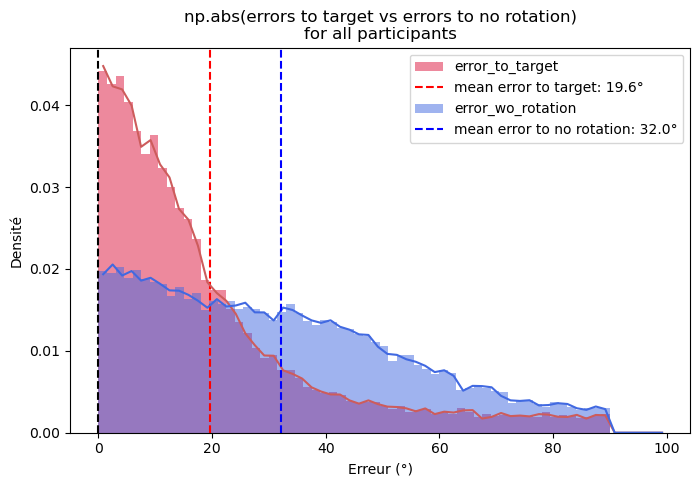

In [53]:
plt.figure(figsize=(8, 5))

plt.hist(np.rad2deg(errors_target_all_hist_abs), bins=60, alpha=0.5, density=True, color="crimson", label="error_to_target")
plt.axvline(np.rad2deg(np.nanmean(errors_target_all_hist_abs)), color='red', linestyle='--', label = f"mean error to target: {np.rad2deg(np.nanmean(errors_target_all_hist_abs)):.1f}°")
plt.plot(np.rad2deg(centers_abs), mean_target_abs*np.pi/180, color="indianred")
# plt.fill_between(centers, mean_target - std_target, mean_target + std_target,
#                  color="red", alpha=0.1)


plt.hist(np.rad2deg(errors_wo_rot_all_hist_abs), bins=60, alpha=0.5, density=True, color="royalblue", label="error_wo_rotation")
plt.plot(np.rad2deg(centers_abs), mean_wo_abs*np.pi/180, color="royalblue")
# plt.fill_between(centers, mean_wo - std_wo, mean_wo + std_wo,
#                  color="blue", alpha=0.1)

plt.axvline(np.rad2deg(np.nanmean(errors_wo_rot_all_hist_abs)), color='blue', linestyle='--', label = f"mean error to no rotation: {np.rad2deg(np.nanmean(errors_wo_rot_all_hist_abs)):.1f}°")

plt.axvline(0, color='black', linestyle='--')
plt.legend()
plt.xlabel("Erreur (°)")
plt.ylabel("Densité")
plt.title("np.abs(errors to target vs errors to no rotation)\nfor all participants")
plt.show()

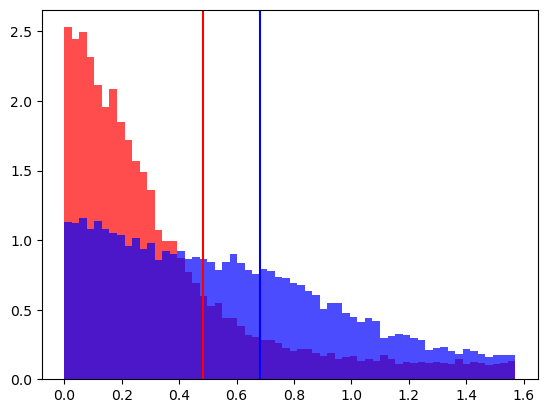

In [54]:
plt.hist(errors_target_all_hist_abs, bins=60, alpha=0.7, density=True, color="red", label="error_to_target")
plt.hist(errors_wo_rot_all_hist_abs, bins=60, alpha=0.7, density=True, color="blue", label="error_wo_rotation")
plt.axvline(np.rad2deg(circular_std_rad(np.deg2rad(errors_wo_rot_all))), color="blue")
plt.axvline(np.rad2deg(circular_std_rad(np.deg2rad(errors_target_all))), color="red")
plt.show()

In [55]:
mean_error_target_per_part_abs = [np.nanmean(errors_target_all_abs[i]) for i in range(len(errors_target_all_abs))]
mean_error_wo_rot_per_part_abs = [np.nanmean(errors_wo_rot_all_abs[i]) for i in range(len(errors_wo_rot_all_abs))]

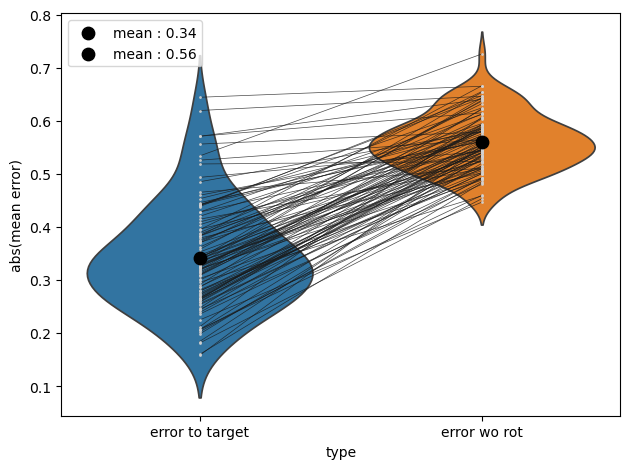

In [56]:
data_target = mean_error_target_per_part_abs
data_wo_rot = mean_error_wo_rot_per_part_abs
df_plot = pd.DataFrame({
    "Mean absolute error (rad)": list(data_target) + list(data_wo_rot),
    "type": ["error to target"]*len(data_target) + ["error wo rot"]*len(data_wo_rot)
})


sns.violinplot(data=df_plot, x="type", y="Mean absolute error (rad)", hue = "type", inner=None, legend = False)
sns.stripplot(data=df_plot, x="type", y="Mean absolute error (rad)", color="lightgrey", jitter = False, alpha=0.9, s=2)
means = df_plot.groupby("type")["Mean absolute error (rad)"].mean()

for i, (group, m) in enumerate(means.items()):
    plt.scatter(i, m, color="black", s=80, zorder=3, label = f'mean : {m:.2f}')

x1, x2 = 0, 1

# lignes appariées
for i in range(len(data_target)):
    plt.plot([x1, x2], [data_target[i], data_wo_rot[i]],
             color="#1A1A1A", alpha=0.8, zorder=1, linewidth=0.5)


# # annotation stats
# y_max = max(np.max(data1), np.max(data2))
# y = y_max * 1.1

# def stars(p):
#     if p < 0.001: return "***"
#     elif p < 0.01: return "**"
#     elif p < 0.05: return "*"
#     else: return "ns"

# plt.plot([x1, x2], [y, y], color='black')
# plt.text(0.5, y, stars(p), ha='center', va='bottom', fontsize=14)

# _____
plt.xticks([x1, x2], ["error to target", "error wo rot"])
plt.legend()
plt.ylabel("abs(mean error)")

plt.tight_layout()
plt.show()


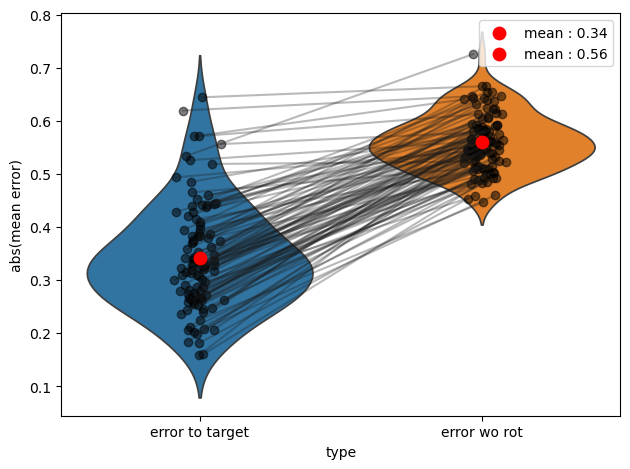

In [57]:
data_target = mean_error_target_per_part_abs
data_wo_rot = mean_error_wo_rot_per_part_abs
df_plot = pd.DataFrame({
    "Mean absolute error (rad)": list(data_target) + list(data_wo_rot),
    "type": ["error to target"]*len(data_target) + ["error wo rot"]*len(data_wo_rot)
})


sns.violinplot(data=df_plot, x="type", y="Mean absolute error (rad)", hue = "type", inner=None, legend = False)
# sns.stripplot(data=df_plot, x="type", y="Mean absolute error (rad)", color="black", alpha=0.4)
means = df_plot.groupby("type")["Mean absolute error (rad)"].mean()

for i, (group, m) in enumerate(means.items()):
    plt.scatter(i, m, color="red", s=80, zorder=3, label = f'mean : {m:.2f}')

x1 = np.random.normal(0, 0.04, size=len(data_target))
x2 = np.random.normal(1, 0.04, size=len(data_wo_rot))

# scatter
plt.scatter(x1, data_target, color="black", alpha=0.5)
plt.scatter(x2, data_wo_rot, color="black", alpha=0.5)

# lignes appariées
for i in range(len(data_target)):
    plt.plot([x1[i], x2[i]], [data_target[i], data_wo_rot[i]],
             color="#1A1A1A", alpha=0.3)
# # annotation stats
# y_max = max(np.max(data1), np.max(data2))
# y = y_max * 1.1

# def stars(p):
#     if p < 0.001: return "***"
#     elif p < 0.01: return "**"
#     elif p < 0.05: return "*"
#     else: return "ns"

# plt.plot([x1, x2], [y, y], color='black')
# plt.text(0.5, y, stars(p), ha='center', va='bottom', fontsize=14)

# _____
# plt.xticks([x1, x2], ["error to target", "error wo rot"])
plt.legend()
plt.ylabel("abs(mean error)")

plt.tight_layout()
plt.show()


In [58]:
from scipy.stats import shapiro

diff = np.array(mean_error_target_per_part_abs) - np.array(mean_error_wo_rot_per_part_abs)
print("les données ne suivent pas une distribution normale :",shapiro(diff))

from scipy.stats import wilcoxon
from scipy.stats import ttest_rel

results = {}
stat, p = wilcoxon(data_target, data_wo_rot)

results = {
    "test" : "Wilcoxon",
    "stat": stat,
    "p": p,
    "mean_target": np.mean(data_target),
    "mean_wo_rot": np.mean(data_wo_rot)
}


results

les données ne suivent pas une distribution normale : ShapiroResult(statistic=0.9638161810541229, pvalue=0.0061063347059139815)


{'test': 'Wilcoxon',
 'stat': 0.0,
 'p': 8.530137789278572e-19,
 'mean_target': 0.3417409571584274,
 'mean_wo_rot': 0.5592947751896037}

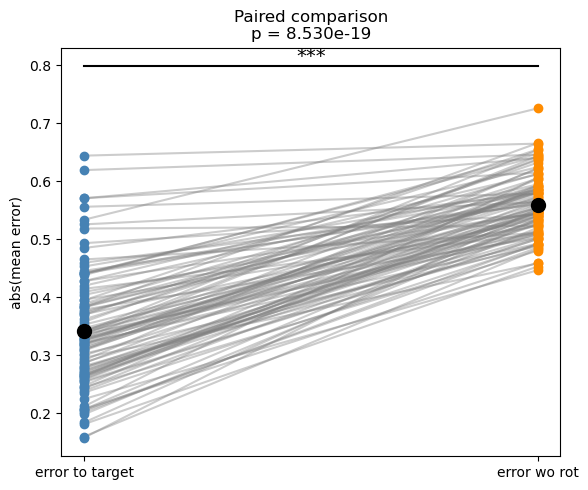

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

data1 = np.array(mean_error_target_per_part_abs)
data2 = np.array(mean_error_wo_rot_per_part_abs)

# test
stat, p = wilcoxon(data1, data2)

# plot
plt.figure(figsize=(6,5))

# positions
x1, x2 = 0, 1

# lignes appariées
for i in range(len(data1)):
    plt.plot([x1, x2], [data1[i], data2[i]],
             color='grey', alpha=0.4, zorder=1)

# points
plt.scatter(np.zeros(len(data1)), data1, color="steelblue", label="error to target", zorder=2)
plt.scatter(np.ones(len(data2)), data2, color="darkorange", label="error wo rot", zorder=2)

# moyennes
m1 = np.mean(data1)
m2 = np.mean(data2)

plt.scatter(x1, m1, color="black", s=100, zorder=3)
plt.scatter(x2, m2, color="black", s=100, zorder=3)

# annotation stats
y_max = max(np.max(data1), np.max(data2))
y = y_max * 1.1

def stars(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    else: return "ns"

plt.plot([x1, x2], [y, y], color='black')
plt.text(0.5, y, stars(p), ha='center', va='bottom', fontsize=14)

# axes
plt.xticks([x1, x2], ["error to target", "error wo rot"])
plt.ylabel("abs(mean error)")
plt.title(f"Paired comparison\np = {p:.3e}")

plt.tight_layout()
plt.show()

/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented

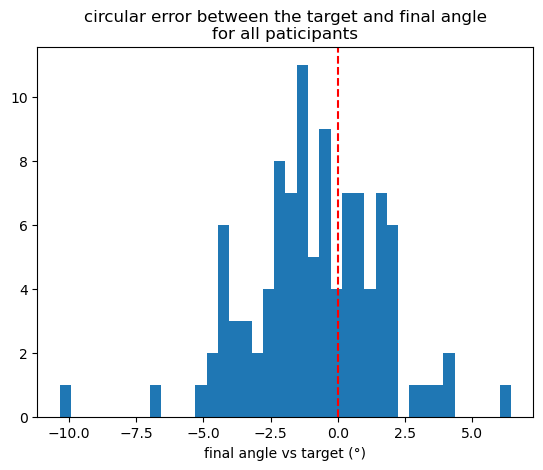

In [60]:
mean_errors_per_participant = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    errors = df_part["error_to_target"].values
    mean_errors_per_participant.append(errors)

error_matrix = np.full((len(mean_errors_per_participant), max(len(errors) for errors in mean_errors_per_participant)), np.nan)

for i, errors in enumerate(mean_errors_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(np.rad2deg(mean_par_sujet("error_to_target")), bins=40)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("final angle vs target (°)")
plt.title("circular error between the target and final angle\nfor all paticipants")
plt.show()

In [61]:
mean_errors_per_participant

[array([-0.24214853,  0.08804038, -0.46358859,  0.01309293,  0.24641774,
         0.1707568 , -0.25671184, -0.84496051, -0.00338866,  0.22228974,
        -1.1285023 ,  0.00274607, -0.38318053, -0.05630562, -0.0481015 ,
        -0.54576085,  0.05856286,  0.54385168, -0.55275403,  0.12602716,
        -0.44418061,  0.38062363,  0.15065541, -0.23501092,  0.27455817,
        -0.08910527, -0.29489907, -0.08375161, -0.22109288,  0.31492479,
         0.2763447 , -0.43021073,  0.33594425, -0.20946658, -0.28619047,
         0.81779039, -0.21853295,  0.15308432,  0.41969311,  0.63065029,
        -0.03366531,  0.34844134,  0.15065378,  0.40213702,  0.2577061 ,
        -0.13426341,  0.13402056, -0.26714792, -0.13213569, -0.13791883,
        -0.06317154,  0.15066571,  0.06768515, -0.00399155, -0.28607168,
        -0.02980715, -0.08591407,  0.06209087,  0.22986938, -0.92135469,
         0.06483354,  0.21300803,  0.79192722, -0.18489272,  0.06590631,
        -0.0053258 ,  0.04005167, -0.14391855,  0.0

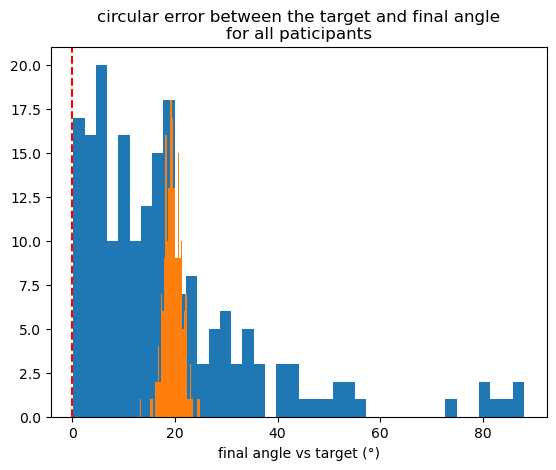

In [62]:
mean_errors_per_participant = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    errors = np.abs(df_part["error_to_target"].values)
    mean_errors_per_participant.append(errors)

error_matrix = np.full((len(mean_errors_per_participant), max(len(errors) for errors in mean_errors_per_participant)), np.nan)

for i, errors in enumerate(mean_errors_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(np.rad2deg(df_part["error_to_target"].apply(np.abs).values), bins=40)
plt.hist(np.rad2deg(m_for_plot), bins=40)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("final angle vs target (°)")
plt.title("circular error between the target and final angle\nfor all paticipants")
plt.show()

In [63]:
from scipy.stats import circstd

def sd_par_sujet_circulaire(column, unit="deg"):
    sd_circulaire = pd.Series(dtype=float)

    for participant in range(104):
        angles = all_participants(dfs[participant])[column].dropna().to_numpy()

        if unit == "deg":
            # données en degrés : borne 0 à 360
            sd_circulaire[participant] = circstd(angles, high=360, low=0)
        elif unit == "rad":
            # données en radians : borne 0 à 2pi
            sd_circulaire[participant] = circstd(angles, high=2*np.pi, low=0)
        else:
            raise ValueError("unit doit être 'deg' ou 'rad'")

    return sd_circulaire

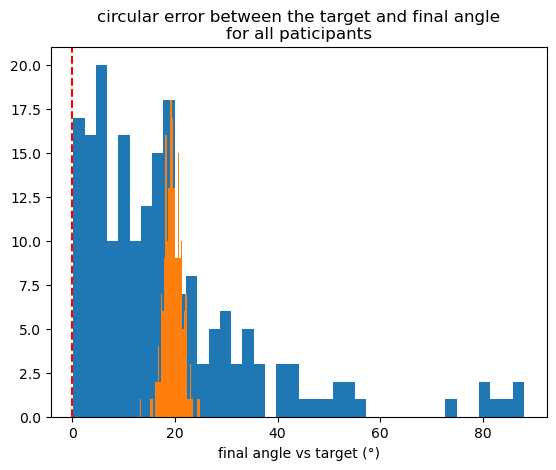

In [64]:
mean_errors_per_participant = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    errors = np.abs(df_part["error_to_target"].values)
    mean_errors_per_participant.append(errors)

error_matrix = np.full((len(mean_errors_per_participant), max(len(errors) for errors in mean_errors_per_participant)), np.nan)

for i, errors in enumerate(mean_errors_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(np.rad2deg(df_part["error_to_target"].apply(np.abs).values), bins=40)
plt.hist(np.rad2deg(m_for_plot), bins=40)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("final angle vs target (°)")
plt.title("circular error between the target and final angle\nfor all paticipants")
plt.show()

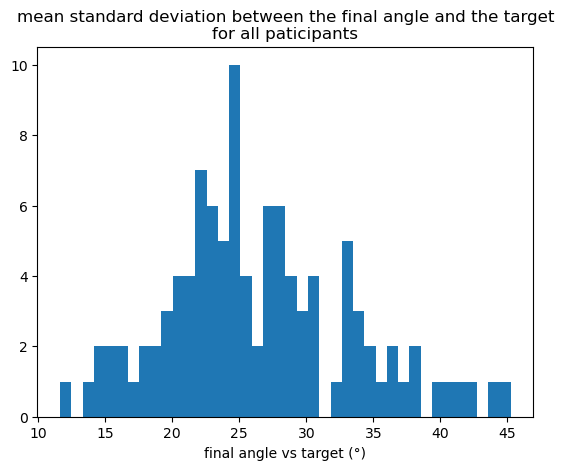

In [65]:
mean_sd_per_participant = []

for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    errors = df_part["error_to_target"].values
    mean_sd_per_participant.append(errors)

error_matrix = np.full((len(mean_sd_per_participant), max(len(errors) for errors in mean_sd_per_participant)), np.nan)

for i, errors in enumerate(mean_sd_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(np.rad2deg(sd_par_sujet_circulaire("error_to_target", unit = 'rad')), bins=40)
plt.xlabel("final angle vs target (°)")
plt.title("mean standard deviation between the final angle and the target\nfor all paticipants")
plt.show()
# pk l'écart type est pas à 0 ? parce que les participants font pas tous la même erreur, certains font des erreurs plus grandes que d'autres, et ça fait que la moyenne de l'écart type est pas nulle.

### rotation error

/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented

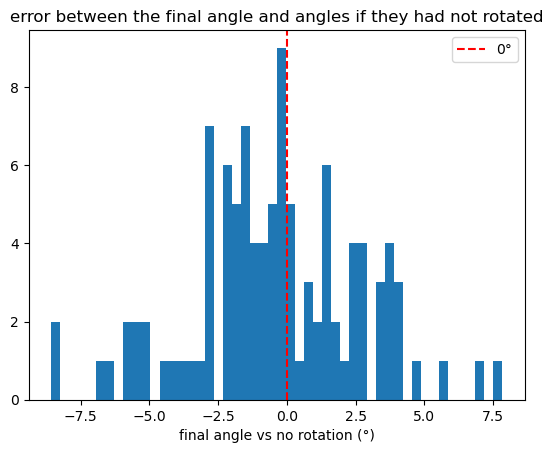

In [66]:
plt.hist(np.rad2deg(mean_par_sujet("error_wo_rotation")), bins=50)
# plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
# plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(0, color='red', linestyle='--', label="0°") 

plt.xlabel("final angle vs no rotation (°)")
plt.title("error between the final angle and angles if they had not rotated")
plt.legend()
plt.show()

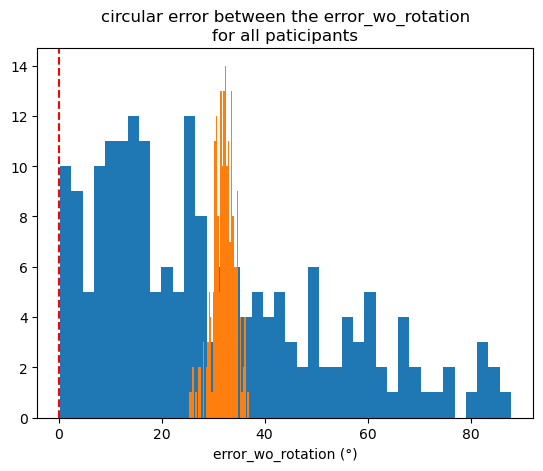

In [67]:
mean_errors_per_participant = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    errors = np.abs(df_part["error_wo_rotation"].values)
    mean_errors_per_participant.append(errors)

error_matrix = np.full((len(mean_errors_per_participant), max(len(errors) for errors in mean_errors_per_participant)), np.nan)

for i, errors in enumerate(mean_errors_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot_wo = np.nanmean(error_matrix, axis=0)

plt.hist(np.rad2deg(df_part["error_wo_rotation"].apply(np.abs).values), bins=40)
plt.hist(np.rad2deg(m_for_plot_wo), bins=40)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("error_wo_rotation (°)")
plt.title("circular error between the error_wo_rotation\nfor all paticipants")
plt.show()

/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/3439997147.py:4: PerformanceWarning: DataFrame is highly fragmented

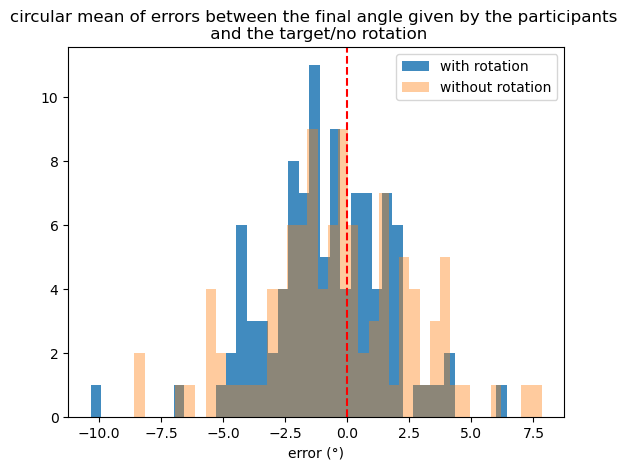

In [68]:
plt.hist(np.rad2deg(mean_par_sujet("error_to_target")), bins=40, label="with rotation", alpha = 0.85)
plt.hist(np.rad2deg(mean_par_sujet("error_wo_rotation")), bins=40, label="without rotation", alpha = 0.4)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("error (°)")
plt.title("circular mean of errors between the final angle given by the participants \n and the target/no rotation")
plt.legend()
plt.show()

(array([ 1.,  1.,  2.,  0.,  1.,  0.,  2.,  2.,  0.,  3.,  0.,  2.,  3.,
         5.,  4.,  1.,  5., 11., 12.,  8.,  5., 13., 10., 13., 14., 10.,
        11.,  7., 13.,  8.,  6.,  6.,  9.,  0.,  4.,  1.,  2.,  4.,  0.,
         1.]),
 array([25.35911787, 25.64837078, 25.93762368, 26.22687658, 26.51612948,
        26.80538238, 27.09463528, 27.38388818, 27.67314108, 27.96239398,
        28.25164688, 28.54089978, 28.83015268, 29.11940558, 29.40865848,
        29.69791138, 29.98716428, 30.27641718, 30.56567008, 30.85492298,
        31.14417588, 31.43342878, 31.72268168, 32.01193458, 32.30118748,
        32.59044038, 32.87969328, 33.16894618, 33.45819908, 33.74745198,
        34.03670488, 34.32595778, 34.61521068, 34.90446358, 35.19371648,
        35.48296938, 35.77222228, 36.06147518, 36.35072808, 36.63998098,
        36.92923388]),
 <BarContainer object of 40 artists>)

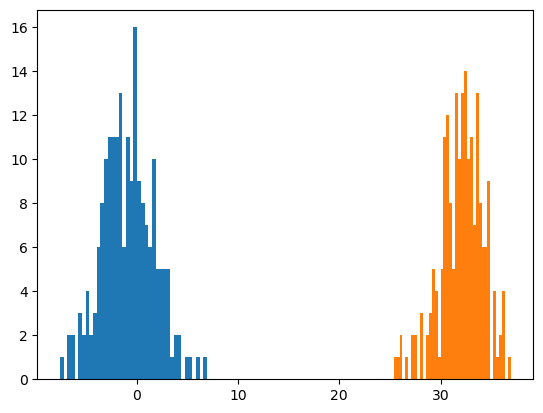

In [69]:
plt.hist(np.rad2deg(m_for_plot), bins=40)
plt.hist(np.rad2deg(m_for_plot_wo), bins=40)


/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/2054817294.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/2054817294.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/2054817294.py:4: PerformanceWarning: DataFrame is highly fragmented

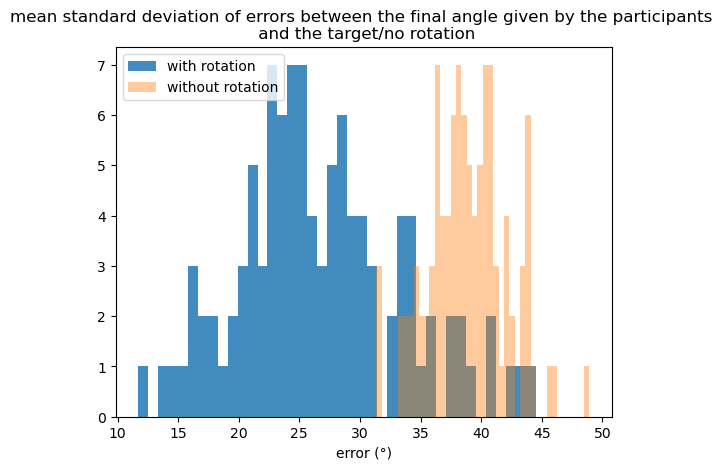

In [70]:
plt.hist(np.rad2deg(sd_par_sujet("error_to_target")), bins=40, label="with rotation", alpha = 0.85)
plt.hist(np.rad2deg(sd_par_sujet("error_wo_rotation")), bins=40, label="without rotation", alpha = 0.4)
plt.xlabel("error (°)")
plt.legend()
plt.title("mean standard deviation of errors between the final angle given by the participants \n and the target/no rotation")
plt.show()

### rotations

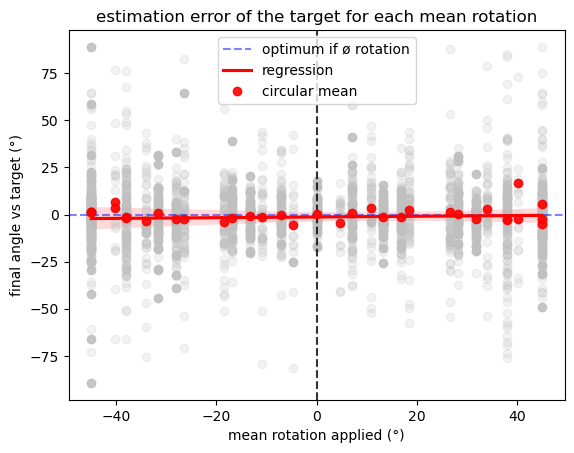

In [71]:
participant_means = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    df_part["error_to_target"] = df_part["error_to_target"].apply(np.rad2deg)
    df_part["mean_rotation"] = df_part["mean_rotation"].apply(np.rad2deg)
    mean_by_rotation = df_part.groupby("mean_rotation")["error_to_target"].mean().reset_index()
    mean_by_rotation["participant"] = participant
    participant_means.append(mean_by_rotation)

df_means_all = pd.concat(participant_means, axis=0)
df_global_mean = df_means_all.groupby("mean_rotation")["error_to_target"].mean().reset_index()

for participant in df_means_all["participant"].unique():
    df_part = df_means_all[df_means_all["participant"] == participant]
    plt.plot(df_part["mean_rotation"], df_part["error_to_target"], 'o', color="silver", alpha=0.2)


plt.axhline(0, color="blue", linestyle="--" , label= "optimum if ø rotation", alpha = 0.5, linewidth =1.5) 
plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_to_target"].apply(np.rad2deg), color="silver", scatter_kws={'alpha':0.9}, line_kws={"color":"red", "label":"regression"})
plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_to_target"], 'o', color="red", label="circular mean", linewidth = 1, alpha = 0.9)

plt.xlabel("mean rotation applied (°)")
plt.ylabel("final angle vs target (°)")
plt.title("estimation error of the target for each mean rotation")
plt.legend()
plt.show()

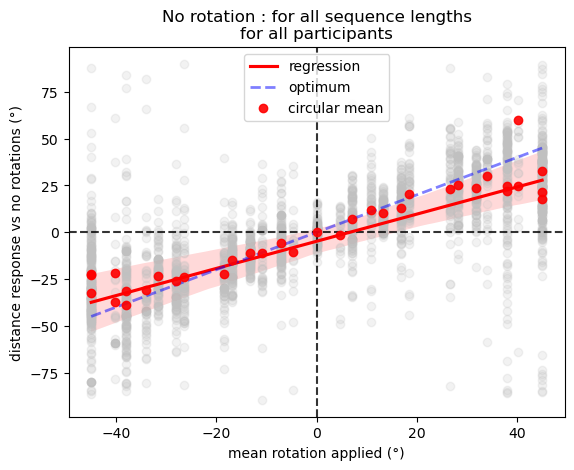

In [72]:
participant_means = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    df_part["error_wo_rotation"] = df_part["error_wo_rotation"].apply(np.rad2deg)
    df_part["mean_rotation"] = df_part["mean_rotation"].apply(np.rad2deg)
    mean_by_rotation = df_part.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()
    mean_by_rotation["participant"] = participant
    participant_means.append(mean_by_rotation)

df_means_all = pd.concat(participant_means, axis=0)
df_global_mean = df_means_all.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()

for participant in df_means_all["participant"].unique():
    df_part = df_means_all[df_means_all["participant"] == participant]
    plt.plot(df_part["mean_rotation"], df_part["error_wo_rotation"], 'o', color="silver", alpha=0.2)


plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_part, color="silver", scatter_kws={'alpha':0.9}, line_kws={"color":"red", "label":"regression"})

borne = df_global_mean["mean_rotation"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_wo_rotation"], 'o', color="red", label="circular mean", linewidth = 1, alpha = 0.9)


plt.xlabel("mean rotation applied (°)")
plt.ylabel("distance response vs no rotations (°)")
plt.title("No rotation : for all sequence lengths\nfor all participants")
plt.legend()
plt.show()

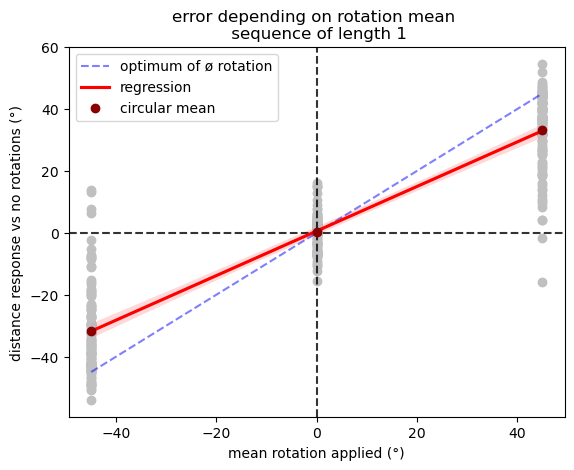

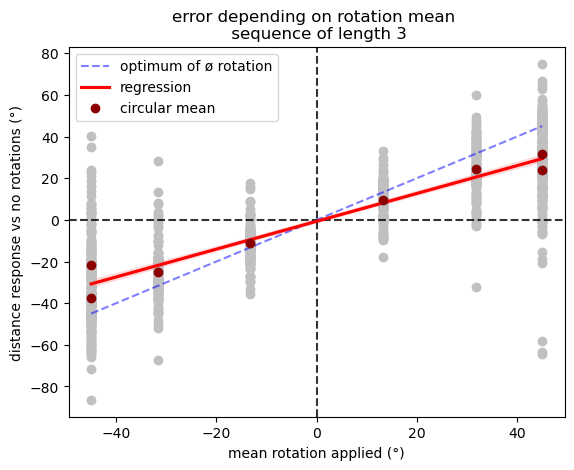

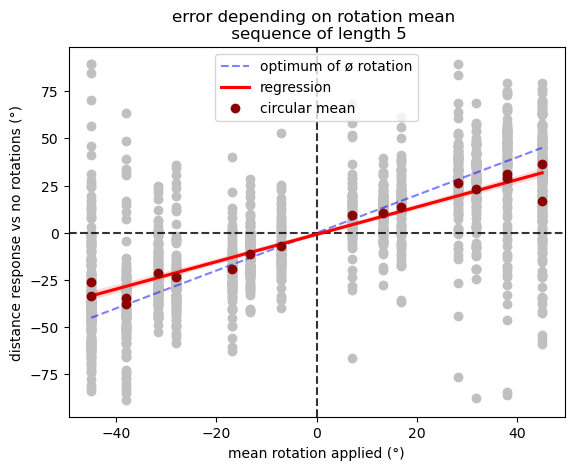

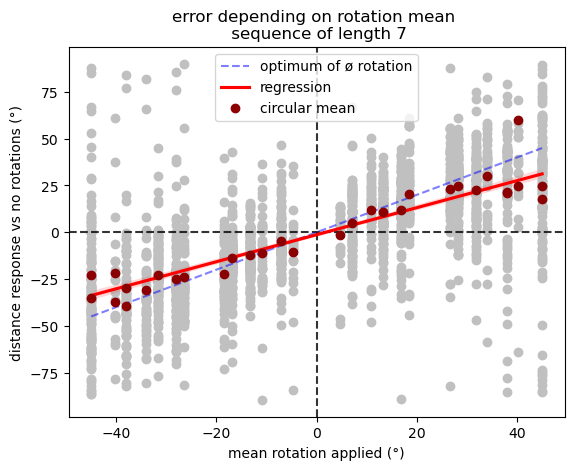

In [73]:
for seqlen in [1,3,5,7] :
    plt.figure()
    participant_means = []

    for participant in range(104):
        df_part = all_participants(dfs[participant])
        df_part["error_wo_rotation"] = df_part["error_wo_rotation"].apply(np.rad2deg)
        df_part["mean_rotation"] = df_part["mean_rotation"].apply(np.rad2deg)
        df_part = df_part[df_part["length of sequence"]==seqlen]
        mean_by_rotation = df_part.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()
        mean_by_rotation["participant"] = participant
        participant_means.append(mean_by_rotation)

    df_means_all = pd.concat(participant_means, axis=0)
    df_global_mean = df_means_all.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()

    for participant in df_means_all["participant"].unique():
        df_part = df_means_all[df_means_all["participant"] == participant]
        plt.plot(df_part["mean_rotation"], df_part["error_wo_rotation"], 'o', color="silver", alpha=0.2)


    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   


    borne = df_means_all["mean_rotation"]
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum of ø rotation", alpha = 0.5, linewidth =1.5)
    sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_means_all, color="silver", scatter_kws={'alpha':1}, line_kws={"color":"red", "label":"regression"})
    plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_wo_rotation"], 'o', color="darkred", label="circular mean")

 
    plt.xlabel("mean rotation applied (°)")
    plt.ylabel("distance response vs no rotations (°)")
    plt.title(f"error depending on rotation mean \n sequence of length {seqlen}")
    plt.legend()
    plt.show()




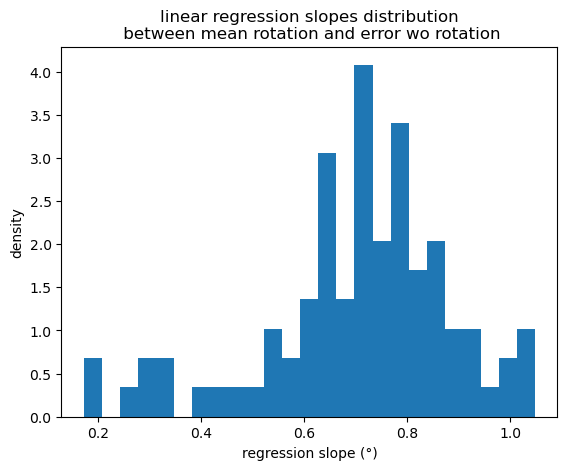

In [74]:
result = []
for participant in range(104):
    df_part = all_participants(dfs[participant])
    df_part["error_wo_rotation"] = df_part["error_wo_rotation"].apply(np.rad2deg)
    df_part["mean_rotation"] = df_part["mean_rotation"].apply(np.rad2deg)

    df = df_part[df_part["length of sequence"]!=1]
    x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))
    result.append(linregress(df["mean_rotation"], df["error_wo_rotation"]).slope)
    
plt.hist(result, bins=25, density = True)
plt.title("linear regression slopes distribution\n between mean rotation and error wo rotation")
plt.xlabel("regression slope (°)")
plt.ylabel("density")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/distribution slopes.pdf")
plt.show()

## threshold test : participants scores for tutorial

In [75]:
q1, q2, q3 = np.percentile(scores, [25, 50, 75])
t1, t2 = np.percentile(scores, [33.33, 66.67])
q1

1023.5

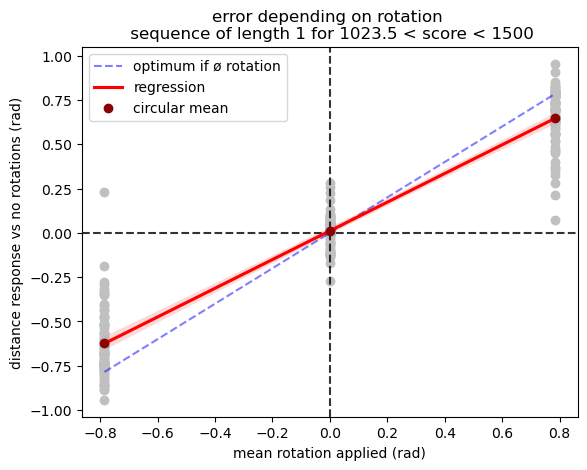

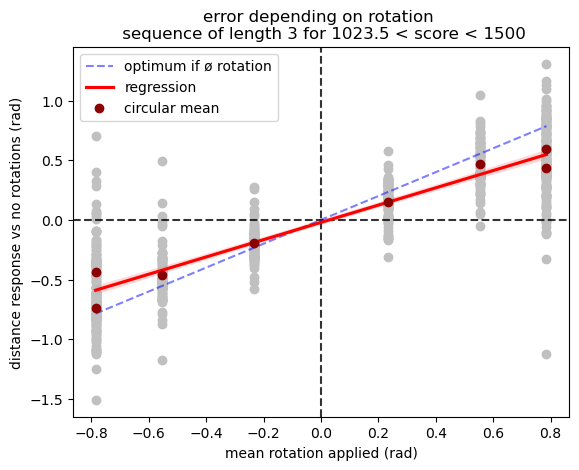

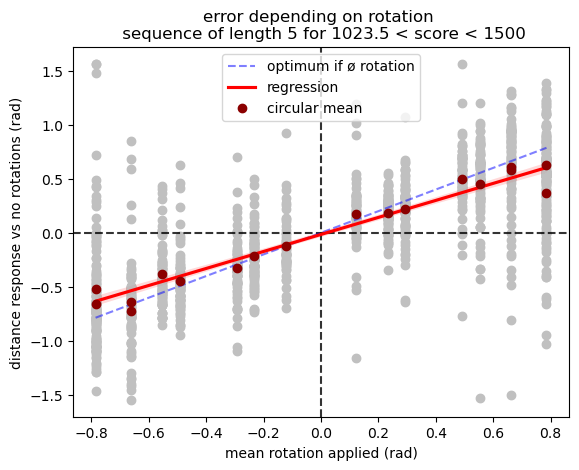

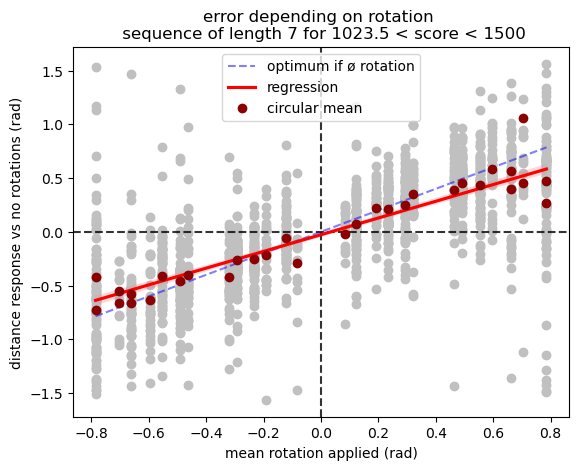

In [76]:
score_min = q1
score_max = 1500

for seqlen in [1,3,5,7] :
    plt.figure()
    participant_means = []

    for participant in range(104):
        df_part = all_participants(dfs[participant])
        score_total = df_part["score"].sum()
        
        if not (score_min <= score_total <= score_max):
            continue
        df_part = df_part[df_part["length of sequence"]==seqlen]
        mean_by_rotation = df_part.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()
        mean_by_rotation["participant"] = participant
        participant_means.append(mean_by_rotation)

    df_means_all = pd.concat(participant_means, axis=0)
    df_global_mean = df_means_all.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()

    for participant in df_means_all["participant"].unique():
        df_part = df_means_all[df_means_all["participant"] == participant]
        plt.plot(df_part["mean_rotation"], df_part["error_wo_rotation"], 'o', color="silver", alpha=0.2)


    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   


    borne = df_means_all["mean_rotation"]
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum if ø rotation", alpha = 0.5, linewidth =1.5)
    sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_means_all, color="silver", scatter_kws={'alpha':1}, line_kws={"color":"red", "label":"regression"})
    plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_wo_rotation"], 'o', color="darkred", label="circular mean")

 
    plt.xlabel("mean rotation applied (rad)")
    plt.ylabel("distance response vs no rotations (rad)")
    plt.title(f"error depending on rotation \n sequence of length {seqlen} for {score_min} < score < {score_max}")
    plt.legend()
    # plt.savefig(f"/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/sequences taille {seqlen}/error rotation pour score < {score_max}.pdf")
    plt.show()




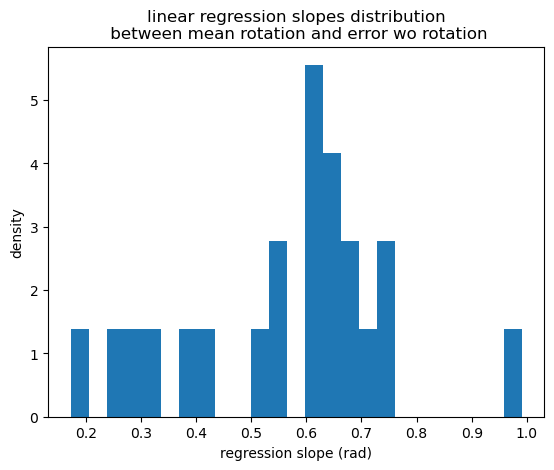

In [77]:
score_min = 700
score_max = t1

result = []
for participant in range(104):
    df_part = all_participants(dfs[participant])
    score_total = df_part["score"].sum()

    if not (score_min <= score_total <= score_max):
        continue
    df = df_part[df_part["length of sequence"]!=1]
    x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))
    result.append(linregress(df["mean_rotation"], df["error_wo_rotation"]).slope)
    
plt.hist(result, bins=25, density = True)
plt.title("linear regression slopes distribution\n between mean rotation and error wo rotation")
plt.xlabel("regression slope (rad)")
plt.ylabel("density")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/distribution slopes.pdf")
plt.show()

In [78]:
import numpy as np
from scipy.optimize import minimize

# ---------------------------
# circular utils
# ---------------------------

def circ_angle(z):
    return np.angle(z) / 2

def circ_complex(theta):
    return np.exp(1j * 2 * theta)

def circular_error(a,b):
    return 0.5*np.angle(np.exp(1j*2*(a-b)))

# ---------------------------
# MODEL SIMULATION
# ---------------------------

def simulate_model(xang, xcue, params, nsmp=200):

    s_sen, g_sen, s_rot, d_rot_p, d_rot_m, s_fac, w_fac_p, w_fac_m, s_int, l_int, s_rep, p_lap = params

    nseq, nang = xang.shape

    z = np.zeros((nseq,nsmp), dtype=complex)

    for i in range(nang):

        valid = ~np.isnan(xang[:,i])
        angles = xang[valid,i]

        if i > 0:
            z[valid] *= 2**(-l_int)

        cues = xcue[valid,i]

        rot = np.zeros_like(angles)

        rot[cues==1] = d_rot_p
        rot[cues==-1] = d_rot_m

        weight = np.ones_like(angles)

        if i > 0:
            weight[cues==1] = w_fac_p
            weight[cues==-1] = w_fac_m

        noise = np.random.normal(0, np.sqrt(s_sen**2+s_rot**2), (len(angles),nsmp))

        ang = angles[:,None] + rot[:,None] + noise

        z[valid] += weight[:,None] * circ_complex(ang)

        if i>0:
            z[valid] += s_int*(np.random.randn(len(angles),nsmp)+1j*np.random.randn(len(angles),nsmp))

    y = circ_angle(z) + np.random.normal(0,s_rep,(nseq,nsmp))

    return y

# ---------------------------
# LIKELIHOOD
# ---------------------------

def log_likelihood(params, xang, xcue, yang):

    y = simulate_model(xang,xcue,params)

    err = circular_error(yang[:,None], y)

    sigma = params[10]

    ll = -0.5*(err/sigma)**2 - np.log(sigma)

    return np.sum(np.log(np.mean(np.exp(ll),axis=1)+1e-12))

# ---------------------------
# NEGATIVE LL FOR FITTING
# ---------------------------

def neg_ll(params, xang, xcue, yang):
    return -log_likelihood(params,xang,xcue,yang)

# ---------------------------
# FIT FUNCTION
# ---------------------------

def fit_model(xang, xcue, yang):

    init = np.array([
        0.1,  # s_sen
        0.0,  # g_sen
        0.1,  # s_rot
        0.7,  # d_rot_p
        -0.7, # d_rot_m
        0.5,  # s_fac
        1.0,  # w_fac_p
        1.0,  # w_fac_m
        0.5,  # s_int
        0.2,  # l_int
        0.2,  # s_rep
        0.05  # p_lap
    ])

    bounds = [
        (0,2),
        (-5,5),
        (0,2),
        (-np.pi/2,np.pi/2),
        (-np.pi/2,np.pi/2),
        (0,5),
        (0,5),
        (0,5),
        (0,5),
        (0,5),
        (1e-3,1),
        (0,0.3)
    ]

    result = minimize(
        neg_ll,
        init,
        args=(xang,xcue,yang),
        bounds=bounds,
        method="L-BFGS-B"
    )

    return result



xang = np.array([np.pad(seq, (0,7-len(seq)), constant_values=np.nan) for seq in df_radian["presented_angles"]])
xcue = np.array([np.pad(np.sign(rot), (0,7-len(rot)), constant_values=np.nan) for rot in df_radian["stimulus_rotations"]])
yang = df_radian["final_angle"].to_numpy()

In [79]:
result = fit_model(xang, xcue, yang)

print(result.x)

[ 0.1   0.    0.1   0.7  -0.7   0.5   1.    1.    0.5   0.2   0.2   0.05]


moyenne de la valeur absolue de l'erreur à la target


In [80]:
# mean_errors_per_participant = []
# mean_wo_rot = []
# for participant in range(len(dfs)):
#     df_part = all_participants(dfs[participant])
#     errors = df_part["error_to_target"].apply(np.abs).values
#     wo_rot = df_part["error_wo_rotation"].apply(np.abs).values
#     mean_errors_per_participant.append(CircularMean(errors))
#     mean_wo_rot.append(CircularMean(wo_rot))
    

# from scipy.stats import wilcoxon

# # for i, errors in enumerate(mean_errors_per_participant):
# #     error_matrix[i, :len(errors)] = errors 
# # m_for_plot = np.nanmean(error_matrix, axis=0)

# plt.hist(np.rad2deg(mean_errors_per_participant), bins=40)
# plt.xlabel("final angle vs target (°)")
# plt.title("circular error between the target and final angle\nfor all paticipants")
# plt.show()


# data_p = mean_errors_per_participant
# data_m = mean_wo_rot
    
# stat, p = wilcoxon(data_p, data_m)


# def stars(p):
#     if p < 0.001:
#         return "***"
#     elif p < 0.01:
#         return "**"
#     elif p < 0.05:
#         return "*"
#     else:
#         return "ns"

# sig = stars(p)


# df_plot = pd.DataFrame({
#     "value": list(data_p) + list(data_m),
#     "condition": ["error to target"]*len(data_p) + ["error wo rot"]*len(data_m)
# })

# sns.violinplot(
#     data=df_plot,
#     x="condition",
#     y="value",
#     inner=None,
#     palette=["lightblue", "lightcoral"]
# )

# sns.stripplot(
#     data=df_plot,
#     x="condition",
#     y="value",
#     color="black",
#     alpha=0.5
# )

# means = df_plot.groupby("condition")["value"].mean()

# for i, m in enumerate(means):
#     plt.scatter(i, m, color="red", s=80, zorder=3, label = f'mean \n {m:.3f}')
# y_max = df_plot["value"].max()
# y = y_max * 1.1


# plt.plot([0, 1], [y, y], color='black')
# plt.text(0.5, y-0.015, sig, ha='center', va='bottom', fontsize=16)
# plt.ylabel("error")
# plt.xlabel("")
# plt.title(f"mean |mean(error to target)| vs |mean(error wo rot)| for all participants\np = {p:.2e}")

# plt.tight_layout()
# plt.legend()
# plt.show()



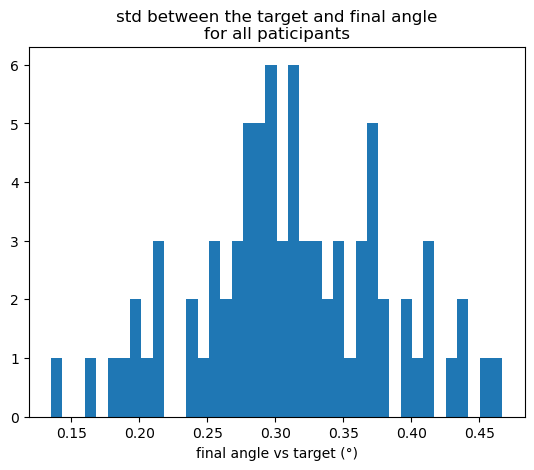

/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_12829/437495308.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


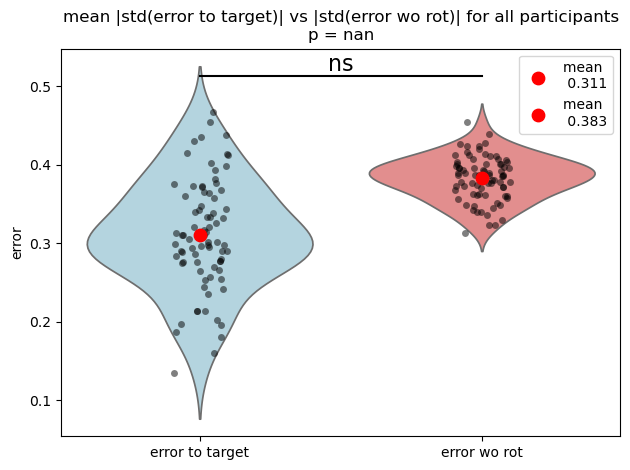

In [81]:
std_errors_per_participant = []
std_wo_rot = []
for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    errors = df_part["error_to_target"].apply(np.abs).values
    wo_rot = df_part["error_wo_rotation"].apply(np.abs).values
    std_errors_per_participant.append(np.std(errors))
    std_wo_rot.append(wo_rot.std())



from scipy.stats import wilcoxon

# for i, errors in enumerate(mean_errors_per_participant):
#     error_matrix[i, :len(errors)] = errors 
# m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(std_errors_per_participant, bins=40)
plt.xlabel("final angle vs target (°)")
plt.title("std between the target and final angle\nfor all paticipants")
plt.show()


    
stat, p = wilcoxon(std_errors_per_participant, std_wo_rot)


def stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

sig = stars(p)


df_plot = pd.DataFrame({
    "value": list(std_errors_per_participant) + list(std_wo_rot),
    "condition": ["error to target"]*len(std_errors_per_participant) + ["error wo rot"]*len(std_wo_rot)
})

sns.violinplot(
    data=df_plot,
    x="condition",
    y="value",
    inner=None,
    palette=["lightblue", "lightcoral"]
)

sns.stripplot(
    data=df_plot,
    x="condition",
    y="value",
    color="black",
    alpha=0.5
)

means = df_plot.groupby("condition")["value"].mean()

for i, m in enumerate(means):
    plt.scatter(i, m, color="red", s=80, zorder=3, label = f'mean \n {m:.3f}')
y_max = df_plot["value"].max()
y = y_max * 1.1


plt.plot([0, 1], [y, y], color='black')
plt.text(0.5, y, sig, ha='center', va='bottom', fontsize=16)
plt.ylabel("error")
plt.xlabel("")
plt.title(f"mean |std(error to target)| vs |std(error wo rot)| for all participants\np = {p:.2e}")

plt.tight_layout()
plt.legend()
plt.show()